# 07. Label Delay Simulation

## Objectives

This notebook simulates delayed label availability for
fraud detection on evolving data streams.

The main objectives are:

1. Generate deterministic label schedules for IEEE-CIS
   and all six BAF variants.
2. Measure label availability at each evaluation block.
3. Analyze the impact of label delay and training window
   size on eligible training samples.
4. Verify temporal consistency and prevent label leakage.
5. Export reproducible simulation artifacts and reports.

## Experimental Protocol

### IEEE-CIS

- Fixed label delays: 0, 7, 14, and 30 days.
- Training windows: 30, 60, and 90 days.
- Decision time: beginning of each evaluation block.
- Label availability: strictly before decision time.
- Common pre-labeled warmup.
- Recent event training window.

### BAF

- Fixed label delays: 0, 1, and 2 months.
- Training windows: 2 and 3 months.
- Monthly batch label release.
- Common pre-labeled warmup.

## Scope

This notebook analyzes training data availability only.
Model training, drift detection, and retraining policy
evaluation are performed in subsequent stages.

## 1. Environment Setup

Import required libraries, initialize the project root,
load the dataset configuration, and prepare output
directories.

In [1]:
import sys
import gc
import json
import hashlib

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [2]:
# Locate project root

PROJECT_ROOT = Path.cwd().resolve()

while not (PROJECT_ROOT / "configs" / "dataset.yaml").exists():

    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise FileNotFoundError("Project root could not be located.")

    PROJECT_ROOT = PROJECT_ROOT.parent


if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_ROOT),
    )


print("Project root:", PROJECT_ROOT)

Project root: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining


In [3]:
from src.data_loader import load_config

from src.label_delay import (
    build_ieee_label_schedule,
    build_baf_label_schedule,
    get_ieee_available_mask,
    get_baf_available_mask,
    get_ieee_training_mask,
    get_baf_training_mask,
    select_training_rows,
    get_initial_training_rows,
    summarize_training_data,
    validate_ieee_label_schedule,
    validate_baf_label_schedule,
)

### Load configuration

In [4]:
config = load_config()

paths_cfg = config["paths"]

ieee_cfg = config["datasets"]["ieee_cis"]

temporal_cfg = config["temporal_split"]
baf_temporal_cfg = config["baf_temporal_split"]

sim_cfg = config["simulation"]
baf_sim_cfg = config["baf_simulation"]


SECONDS_PER_DAY = ieee_cfg["seconds_per_day"]

IEEE_DELAYS = sim_cfg["label_delay_days"]

IEEE_WINDOWS = sim_cfg["training_window_days"]

BAF_DELAYS = baf_sim_cfg["label_delay_months"]

BAF_WINDOWS = baf_sim_cfg["training_window_months"]


BAF_VARIANTS = [
    "base",
    "variant_i",
    "variant_ii",
    "variant_iii",
    "variant_iv",
    "variant_v",
]


print("IEEE-CIS delays:", IEEE_DELAYS)
print("IEEE-CIS windows:", IEEE_WINDOWS)

print("BAF delays:", BAF_DELAYS)
print("BAF windows:", BAF_WINDOWS)

print("BAF variants:", BAF_VARIANTS)

IEEE-CIS delays: [0, 7, 14, 30]
IEEE-CIS windows: [30, 60, 90]
BAF delays: [0, 1, 2]
BAF windows: [2, 3]
BAF variants: ['base', 'variant_i', 'variant_ii', 'variant_iii', 'variant_iv', 'variant_v']


### Initialize paths và Display settings

In [5]:
PROCESSED_DIR = PROJECT_ROOT / paths_cfg["processed_dir"]

TEMPORAL_DIR = PROJECT_ROOT / paths_cfg["temporal_dir"]

TEMPORAL_REPORT_DIR = PROJECT_ROOT / paths_cfg["temporal_report_dir"]

LABEL_SCHEDULE_DIR = PROJECT_ROOT / paths_cfg["label_schedule_dir"]

REPORT_DIR = PROJECT_ROOT / paths_cfg["label_delay_report_dir"]

FIGURE_DIR = PROJECT_ROOT / paths_cfg["figures_dir"] / "label_delay"


IEEE_SCHEDULE_DIR = LABEL_SCHEDULE_DIR / "ieee"

BAF_SCHEDULE_DIR = LABEL_SCHEDULE_DIR / "baf"


for directory in [
    IEEE_SCHEDULE_DIR,
    BAF_SCHEDULE_DIR,
    REPORT_DIR,
    FIGURE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


print("Processed:", PROCESSED_DIR)
print("Temporal:", TEMPORAL_DIR)
print("Schedules:", LABEL_SCHEDULE_DIR)
print("Reports:", REPORT_DIR)
print("Figures:", FIGURE_DIR)

Processed: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\data\processed
Temporal: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\data\temporal
Schedules: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\data\simulations\label_schedules
Reports: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\label_delay
Figures: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\figures\label_delay


In [6]:
pd.set_option(
    "display.max_columns",
    50,
)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.4f}",
)

sns.set_theme(
    style="whitegrid",
    context="notebook",
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11


IEEE_DELAY_PALETTE = {
    0: "#2563EB",
    7: "#16A34A",
    14: "#F59E0B",
    30: "#DC2626",
}

BAF_DELAY_PALETTE = {
    0: "#2563EB",
    1: "#F59E0B",
    2: "#DC2626",
}

## 2. Load Input Data

The temporal indices generated in Step 4 are used to
construct label schedules.

Only identifier, event time, and ground-truth columns
are loaded from the processed datasets.

The full feature matrices are not required for label
availability analysis.

In [7]:
print("Processed Parquet files:")

for path in sorted(PROCESSED_DIR.rglob("*.parquet")):
    print(path.relative_to(PROJECT_ROOT))


print("\nTemporal Parquet files:")

for path in sorted(TEMPORAL_DIR.rglob("*.parquet")):
    print(path.relative_to(PROJECT_ROOT))

Processed Parquet files:
data\processed\baf\base.parquet
data\processed\baf\variant_i.parquet
data\processed\baf\variant_ii.parquet
data\processed\baf\variant_iii.parquet
data\processed\baf\variant_iv.parquet
data\processed\baf\variant_v.parquet
data\processed\ieee_full.parquet
data\processed\ieee_nocardid.parquet

Temporal Parquet files:
data\temporal\baf\base_temporal_index.parquet
data\temporal\baf\variant_i_temporal_index.parquet
data\temporal\baf\variant_ii_temporal_index.parquet
data\temporal\baf\variant_iii_temporal_index.parquet
data\temporal\baf\variant_iv_temporal_index.parquet
data\temporal\baf\variant_v_temporal_index.parquet
data\temporal\ieee_temporal_index.parquet


In [8]:
IEEE_PROCESSED_PATH = PROCESSED_DIR / "ieee_nocardid.parquet"

IEEE_TEMPORAL_PATH = TEMPORAL_DIR / "ieee_temporal_index.parquet"

IEEE_BLOCK_MANIFEST_PATH = TEMPORAL_REPORT_DIR / "ieee_block_manifest.csv"

BAF_BLOCK_MANIFEST_PATH = TEMPORAL_REPORT_DIR / "baf_block_manifest.csv"


BAF_PROCESSED_PATHS = {
    variant: (PROCESSED_DIR / "baf" / f"{variant}.parquet") for variant in BAF_VARIANTS
}


BAF_TEMPORAL_PATHS = {
    variant: (TEMPORAL_DIR / "baf" / f"{variant}_temporal_index.parquet")
    for variant in BAF_VARIANTS
}


required_paths = [
    IEEE_PROCESSED_PATH,
    IEEE_TEMPORAL_PATH,
    IEEE_BLOCK_MANIFEST_PATH,
    BAF_BLOCK_MANIFEST_PATH,
    *BAF_PROCESSED_PATHS.values(),
    *BAF_TEMPORAL_PATHS.values(),
]


missing_paths = [str(path) for path in required_paths if not path.exists()]


if missing_paths:
    raise FileNotFoundError("Missing input files:\n" + "\n".join(missing_paths))


print("All required input files exist.")

All required input files exist.


### Load IEEE-CIS

In [9]:
ieee_temporal = pd.read_parquet(IEEE_TEMPORAL_PATH)

ieee_ground_truth = pd.read_parquet(
    IEEE_PROCESSED_PATH,
    columns=[
        "TransactionID",
        "TransactionDT",
        "isFraud",
    ],
)

ieee_manifest = pd.read_csv(IEEE_BLOCK_MANIFEST_PATH)


print(
    "Temporal index:",
    ieee_temporal.shape,
)

print(
    "Ground truth:",
    ieee_ground_truth.shape,
)

print(
    "Block manifest:",
    ieee_manifest.shape,
)


display(ieee_temporal.head())
display(ieee_ground_truth.head())
display(ieee_manifest.head())

Temporal index: (590540, 5)
Ground truth: (590540, 3)
Block manifest: (21, 7)


,TransactionID,TransactionDT,day,phase,block_id
0,2987000,86400,1,warmup,0
1,2987001,86401,1,warmup,0
2,2987002,86469,1,warmup,0
3,2987003,86499,1,warmup,0
4,2987004,86506,1,warmup,0


,TransactionID,TransactionDT,isFraud
0,2987000,86400,0
1,2987001,86401,0
2,2987002,86469,0
3,2987003,86499,0
4,2987004,86506,0


,block_id,phase,start_day,end_day,start_time,end_time_exclusive,duration_days
0,1,validation,31,37,2678400,3283200,7
1,2,validation,38,44,3283200,3888000,7
2,3,validation,45,51,3888000,4492800,7
3,4,validation,52,58,4492800,5097600,7
4,5,validation,59,65,5097600,5702400,7


### Inspect temporal manifest

In [10]:
print("IEEE temporal columns:")

print(ieee_temporal.columns.tolist())


print("\nIEEE manifest columns:")

print(ieee_manifest.columns.tolist())


print("\nPhase distribution:")

display(ieee_temporal["phase"].value_counts())


print("\nBlock distribution:")

display(
    ieee_temporal.groupby(
        ["phase", "block_id"],
        observed=True,
    ).size()
)

IEEE temporal columns:
['TransactionID', 'TransactionDT', 'day', 'phase', 'block_id']

IEEE manifest columns:
['block_id', 'phase', 'start_day', 'end_day', 'start_time', 'end_time_exclusive', 'duration_days']

Phase distribution:


phase
test          274406
validation    169439
warmup        134339
tail           12356
Name: count, dtype: int64[pyarrow]


Block distribution:


phase       block_id
tail        -1           12356
test         9           26932
             10          23006
             11          20946
             12          20846
             13          22051
             14          22459
             15          18782
             16          18597
             17          18507
             18          22021
             19          19997
             20          20525
             21          19737
validation   1           23467
             2           20710
             3           20334
             4           19554
             5           23003
             6           21019
             7           20796
             8           20556
warmup       0          134339
dtype: int64

## 3. Analysis Utilities

Define reusable notebook-level utilities for:

- Aligning ground truth with label schedules.
- Extracting evaluation decision points.
- Computing label availability statistics.
- Computing eligible training sample statistics.
- Recording validation results.

Core label eligibility logic remains implemented in
src/label_delay.py.

### Validation recorder

In [11]:
validation_records = []


def record_validation(
    dataset,
    check,
    passed,
    details="",
):
    """Record a validation result and fail if invalid."""

    result = {
        "dataset": dataset,
        "check": check,
        "passed": bool(passed),
        "details": str(details),
    }

    validation_records.append(result)

    if not passed:
        raise AssertionError(f"[{dataset}] {check}: {details}")

    return result

### Ground-truth alignment

In [12]:
def align_ground_truth(
    schedule,
    ground_truth,
    id_column,
    time_column,
    target_column,
):
    """Align ground truth to schedule order by ID."""

    required = [
        id_column,
        time_column,
        target_column,
    ]

    if not set(required).issubset(ground_truth.columns):
        raise ValueError("Missing ground-truth columns.")

    if schedule[id_column].isna().any():
        raise ValueError("Missing schedule IDs.")

    if ground_truth[id_column].isna().any():
        raise ValueError("Missing ground-truth IDs.")

    if not schedule[id_column].is_unique:
        raise ValueError("Duplicate schedule IDs.")

    if not ground_truth[id_column].is_unique:
        raise ValueError("Duplicate ground-truth IDs.")

    indexed_truth = ground_truth.set_index(id_column)

    aligned = indexed_truth.reindex(schedule[id_column].to_numpy())

    if aligned[required[1:]].isna().any().any():
        raise ValueError("Unmatched IDs or missing values.")

    if not np.array_equal(
        aligned[time_column].to_numpy(),
        schedule[time_column].to_numpy(),
    ):
        raise ValueError("Ground-truth timestamp mismatch.")

    if not aligned[target_column].isin([0, 1]).all():
        raise ValueError("Invalid binary ground truth.")

    return pd.Series(
        aligned[target_column].to_numpy(dtype=np.int8),
        index=schedule.index,
        name=target_column,
    )

### Statistical utilities

In [13]:
def safe_percentage(
    numerator,
    denominator,
):
    """Calculate percentage safely."""

    if denominator == 0:
        return np.nan

    return numerator / denominator * 100


def summarize_mask(
    labels,
    mask,
):
    """Summarize samples selected by a boolean mask."""

    if not labels.index.equals(mask.index):
        raise ValueError("Label-mask index mismatch.")

    if not pd.api.types.is_bool_dtype(mask):
        raise ValueError("Mask must be boolean.")

    if mask.isna().any():
        raise ValueError("Missing values in mask.")

    selected = labels.loc[mask]

    n_samples = len(selected)

    n_fraud = int(selected.sum())

    n_legitimate = n_samples - n_fraud

    if n_samples == 0:
        status = "empty"

    elif n_fraud == 0 or n_legitimate == 0:
        status = "single_class"

    else:
        status = "available"

    return {
        "n_samples": n_samples,
        "n_fraud": n_fraud,
        "n_legitimate": n_legitimate,
        "fraud_rate_pct": safe_percentage(
            n_fraud,
            n_samples,
        ),
        "status": status,
    }

### Extract IEEE-CIS decision points

In [14]:
def build_ieee_decision_points(
    temporal_index,
):
    """Construct decision times from evaluation blocks."""

    evaluation = temporal_index.loc[
        temporal_index["phase"].isin(
            [
                "validation",
                "test",
            ]
        )
    ]

    blocks = (
        evaluation.groupby(
            ["phase", "block_id"],
            observed=True,
        )
        .agg(
            start_day=("day", "min"),
            end_day=("day", "max"),
            n_block_samples=(
                "TransactionID",
                "size",
            ),
        )
        .reset_index()
        .sort_values("start_day")
        .reset_index(drop=True)
    )

    time_origin = int(temporal_cfg["expected_time_origin"])

    blocks["decision_time"] = (
        time_origin + (blocks["start_day"] - 1) * SECONDS_PER_DAY
    ).astype("int64")

    blocks["block_end_exclusive"] = (
        time_origin + blocks["end_day"] * SECONDS_PER_DAY
    ).astype("int64")

    return blocks

### Extract BAF decision points

In [15]:
def build_baf_decision_points(
    temporal_index,
):
    """Construct monthly BAF decision points."""

    evaluation = temporal_index.loc[
        temporal_index["phase"].isin(
            [
                "validation",
                "test",
            ]
        )
    ]

    blocks = (
        evaluation.groupby(
            ["phase", "block_id"],
            observed=True,
        )
        .agg(
            start_month=("month", "min"),
            end_month=("month", "max"),
            n_block_samples=(
                "record_id",
                "size",
            ),
        )
        .reset_index()
        .sort_values("start_month")
        .reset_index(drop=True)
    )

    if not blocks["start_month"].eq(blocks["end_month"]).all():
        raise ValueError("Each BAF block must contain one month.")

    blocks["decision_month"] = blocks["start_month"]

    return blocks

### Validate IEEE-CIS decision points

In [16]:
ieee_decisions = build_ieee_decision_points(ieee_temporal)


record_validation(
    dataset="ieee_cis",
    check="evaluation_block_count",
    passed=len(ieee_decisions) == 21,
    details=len(ieee_decisions),
)

record_validation(
    dataset="ieee_cis",
    check="validation_block_count",
    passed=(ieee_decisions["phase"].eq("validation").sum() == 8),
)

record_validation(
    dataset="ieee_cis",
    check="test_block_count",
    passed=(ieee_decisions["phase"].eq("test").sum() == 13),
)

record_validation(
    dataset="ieee_cis",
    check="weekly_block_length",
    passed=((ieee_decisions["end_day"] - ieee_decisions["start_day"] + 1) == 7).all(),
)

record_validation(
    dataset="ieee_cis",
    check="expected_block_start_days",
    passed=np.array_equal(
        ieee_decisions["start_day"].to_numpy(),
        np.arange(31, 178, 7),
    ),
)

record_validation(
    dataset="ieee_cis",
    check="chronological_decisions",
    passed=(
        ieee_decisions["decision_time"].is_monotonic_increasing
        and ieee_decisions["decision_time"].is_unique
    ),
)


display(ieee_decisions)

,phase,block_id,start_day,end_day,n_block_samples,decision_time,block_end_exclusive
0,validation,1,31,37,23467,2678400,3283200
1,validation,2,38,44,20710,3283200,3888000
2,validation,3,45,51,20334,3888000,4492800
3,validation,4,52,58,19554,4492800,5097600
4,validation,5,59,65,23003,5097600,5702400
5,validation,6,66,72,21019,5702400,6307200
6,validation,7,73,79,20796,6307200,6912000
7,validation,8,80,86,20556,6912000,7516800
8,test,9,87,93,26932,7516800,8121600
9,test,10,94,100,23006,8121600,8726400


## 4. IEEE-CIS Label Schedule Generation

Generate deterministic label schedules for delays of
0, 7, 14, and 30 days.

The schedules contain temporal metadata and simulated
label availability times, but do not contain ground truth.

Warmup transactions follow the common pre-labeled
warmup protocol.

### Generate label schedules

In [17]:
ieee_schedule_records = []

ieee_schedule_paths = {}


for delay in IEEE_DELAYS:

    print(f"Generating IEEE-CIS d={delay}...")

    schedule = build_ieee_label_schedule(
        temporal_index=ieee_temporal,
        delay_days=delay,
    )

    valid = validate_ieee_label_schedule(
        schedule=schedule,
        temporal_index=ieee_temporal,
        delay_days=delay,
    )

    record_validation(
        dataset="ieee_cis",
        check=f"schedule_d{delay}",
        passed=valid,
    )

    output_path = IEEE_SCHEDULE_DIR / f"d{delay}.parquet"

    schedule.to_parquet(
        output_path,
        index=False,
        compression="snappy",
    )

    ieee_schedule_paths[delay] = output_path

    ieee_schedule_records.append(
        {
            "dataset": "ieee_cis",
            "delay_days": delay,
            "n_records": len(schedule),
            "n_pre_labeled": int(schedule["is_pre_labeled"].sum()),
            "min_event_time": int(schedule["TransactionDT"].min()),
            "max_event_time": int(schedule["TransactionDT"].max()),
            "min_label_available_time": int(schedule["label_available_time"].min()),
            "max_label_available_time": int(schedule["label_available_time"].max()),
            "file": str(output_path.relative_to(PROJECT_ROOT)),
        }
    )

    print(f"Saved {len(schedule):,} records")

    del schedule
    gc.collect()


ieee_schedule_summary = pd.DataFrame(ieee_schedule_records)

display(ieee_schedule_summary)

Generating IEEE-CIS d=0...
Saved 590,540 records
Generating IEEE-CIS d=7...
Saved 590,540 records
Generating IEEE-CIS d=14...
Saved 590,540 records
Generating IEEE-CIS d=30...
Saved 590,540 records


,dataset,delay_days,n_records,n_pre_labeled,min_event_time,max_event_time,min_label_available_time,max_label_available_time,file
0,ieee_cis,0,590540,134339,86400,15811131,86400,15811131,data\simulations\label_schedules\ieee\d0.parquet
1,ieee_cis,7,590540,134339,86400,15811131,691200,16415931,data\simulations\label_schedules\ieee\d7.parquet
2,ieee_cis,14,590540,134339,86400,15811131,1296000,17020731,data\simulations\label_schedules\ieee\d14.parquet
3,ieee_cis,30,590540,134339,86400,15811131,2678399,18403131,data\simulations\label_schedules\ieee\d30.parquet


### Inspect one label schedule

In [18]:
sample_schedule = pd.read_parquet(ieee_schedule_paths[7])

display(sample_schedule.head(10))

display(sample_schedule.loc[sample_schedule["phase"].eq("validation")].head(10))

display(sample_schedule.dtypes)

,TransactionID,TransactionDT,day,phase,block_id,label_delay_days,label_available_time,is_pre_labeled
0,2987000,86400,1,warmup,0,7,691200,True
1,2987001,86401,1,warmup,0,7,691201,True
2,2987002,86469,1,warmup,0,7,691269,True
3,2987003,86499,1,warmup,0,7,691299,True
4,2987004,86506,1,warmup,0,7,691306,True
5,2987005,86510,1,warmup,0,7,691310,True
6,2987006,86522,1,warmup,0,7,691322,True
7,2987007,86529,1,warmup,0,7,691329,True
8,2987008,86535,1,warmup,0,7,691335,True
9,2987009,86536,1,warmup,0,7,691336,True


,TransactionID,TransactionDT,day,phase,block_id,label_delay_days,label_available_time,is_pre_labeled
134339,3121339,2678405,31,validation,1,7,3283205,False
134340,3121340,2678413,31,validation,1,7,3283213,False
134341,3121341,2678447,31,validation,1,7,3283247,False
134342,3121342,2678460,31,validation,1,7,3283260,False
134343,3121343,2678487,31,validation,1,7,3283287,False
134344,3121344,2678492,31,validation,1,7,3283292,False
134345,3121345,2678493,31,validation,1,7,3283293,False
134346,3121346,2678496,31,validation,1,7,3283296,False
134347,3121347,2678500,31,validation,1,7,3283300,False
134348,3121348,2678520,31,validation,1,7,3283320,False


TransactionID            int64
TransactionDT            int64
day                      int32
phase                   string
block_id                 int16
label_delay_days         int32
label_available_time     int64
is_pre_labeled            bool
dtype: object

### Verify effective delay

In [19]:
sample_schedule["effective_delay_days"] = (
    sample_schedule["label_available_time"] - sample_schedule["TransactionDT"]
) / SECONDS_PER_DAY


display(
    sample_schedule.groupby(
        "phase",
        observed=True,
    )["effective_delay_days"].agg(
        [
            "min",
            "max",
            "mean",
        ]
    )
)


non_warmup_mask = ~sample_schedule["phase"].eq("warmup")

record_validation(
    dataset="ieee_cis",
    check="d7_effective_delay_after_warmup",
    passed=(
        sample_schedule.loc[
            non_warmup_mask,
            "effective_delay_days",
        ]
        == 7
    ).all(),
)


del sample_schedule
gc.collect()

,min,max,mean
phase,,,
tail,7.0000,7.0000,7.0000
test,7.0000,7.0000,7.0000
validation,7.0000,7.0000,7.0000
warmup,0.0001,7.0000,6.2845


0

## 5. IEEE-CIS Label Availability Analysis

At each evaluation decision time, measure:

- Historical transaction count.
- Available label count.
- Pending label count.
- Label availability ratio.
- Available fraud count.
- Available fraud label ratio.

Ground truth for pending transactions is used only for
retrospective diagnostic statistics. It must not be
exposed to online retraining policies.

### Availability statistics function

In [20]:
def compute_availability_statistics(
    labels,
    historical_mask,
    available_mask,
):
    """Compute online and retrospective statistics."""

    if (available_mask & ~historical_mask).any():
        raise ValueError("Available labels contain future events.")

    pending_mask = historical_mask & ~available_mask

    historical = summarize_mask(
        labels,
        historical_mask,
    )

    available = summarize_mask(
        labels,
        available_mask,
    )

    pending = summarize_mask(
        labels,
        pending_mask,
    )

    return {
        # Observable statistics
        "n_historical": (historical["n_samples"]),
        "n_available": (available["n_samples"]),
        "n_pending": (pending["n_samples"]),
        "label_availability_pct": (
            safe_percentage(
                available["n_samples"],
                historical["n_samples"],
            )
        ),
        "n_available_fraud": (available["n_fraud"]),
        "available_fraud_rate_pct": (available["fraud_rate_pct"]),
        # Retrospective diagnostics only
        "offline_n_historical_fraud": (historical["n_fraud"]),
        "offline_n_pending_fraud": (pending["n_fraud"]),
        "offline_fraud_label_availability_pct": (
            safe_percentage(
                available["n_fraud"],
                historical["n_fraud"],
            )
        ),
    }

### Run IEEE-CIS availability analysis

In [21]:
ieee_availability_records = []


for delay in IEEE_DELAYS:

    schedule = pd.read_parquet(ieee_schedule_paths[delay])

    labels = align_ground_truth(
        schedule=schedule,
        ground_truth=ieee_ground_truth,
        id_column="TransactionID",
        time_column="TransactionDT",
        target_column="isFraud",
    )

    for block in ieee_decisions.itertuples(index=False):

        decision_time = int(block.decision_time)

        historical_mask = schedule["TransactionDT"] < decision_time

        available_mask = get_ieee_available_mask(
            schedule,
            decision_time,
        )

        stats = compute_availability_statistics(
            labels,
            historical_mask,
            available_mask,
        )

        ieee_availability_records.append(
            {
                "dataset": "ieee_cis",
                "delay_days": delay,
                "phase": block.phase,
                "block_id": int(block.block_id),
                "start_day": int(block.start_day),
                "decision_time": decision_time,
                **stats,
            }
        )

    print(f"Completed delay={delay}")

    del schedule, labels
    gc.collect()


ieee_label_availability = pd.DataFrame(ieee_availability_records)


display(ieee_label_availability.head(10))

print(
    "Total records:",
    len(ieee_label_availability),
)

Completed delay=0
Completed delay=7
Completed delay=14
Completed delay=30


,dataset,delay_days,phase,block_id,start_day,decision_time,n_historical,n_available,n_pending,label_availability_pct,n_available_fraud,available_fraud_rate_pct,offline_n_historical_fraud,offline_n_pending_fraud,offline_fraud_label_availability_pct
0,ieee_cis,0,validation,1,31,2678400,134339,134339,0,100.0000,3401,2.5317,3401,0,100.0000
1,ieee_cis,0,validation,2,38,3283200,157806,157806,0,100.0000,4264,2.7021,4264,0,100.0000
2,ieee_cis,0,validation,3,45,3888000,178516,178516,0,100.0000,5085,2.8485,5085,0,100.0000
3,ieee_cis,0,validation,4,52,4492800,198850,198850,0,100.0000,5952,2.9932,5952,0,100.0000
4,ieee_cis,0,validation,5,59,5097600,218404,218404,0,100.0000,6702,3.0686,6702,0,100.0000
5,ieee_cis,0,validation,6,66,5702400,241407,241407,0,100.0000,7835,3.2456,7835,0,100.0000
6,ieee_cis,0,validation,7,73,6307200,262426,262426,0,100.0000,8660,3.3000,8660,0,100.0000
7,ieee_cis,0,validation,8,80,6912000,283222,283222,0,100.0000,9507,3.3567,9507,0,100.0000
8,ieee_cis,0,test,9,87,7516800,303778,303778,0,100.0000,10282,3.3847,10282,0,100.0000
9,ieee_cis,0,test,10,94,8121600,330710,330710,0,100.0000,11180,3.3806,11180,0,100.0000


Total records: 84


### Validate label availability

In [22]:
record_validation(
    dataset="ieee_cis",
    check="availability_record_count",
    passed=(len(ieee_label_availability) == len(IEEE_DELAYS) * len(ieee_decisions)),
)

record_validation(
    dataset="ieee_cis",
    check="availability_count_conservation",
    passed=(
        ieee_label_availability["n_available"] + ieee_label_availability["n_pending"]
        == ieee_label_availability["n_historical"]
    ).all(),
)


d0_availability = ieee_label_availability.loc[
    ieee_label_availability["delay_days"].eq(0)
]

record_validation(
    dataset="ieee_cis",
    check="d0_all_historical_labels_available",
    passed=(d0_availability["n_pending"] == 0).all(),
)


availability_pivot = ieee_label_availability.pivot(
    index="start_day",
    columns="delay_days",
    values="n_available",
).reindex(columns=sorted(IEEE_DELAYS))

record_validation(
    dataset="ieee_cis",
    check="availability_monotonic_across_delays",
    passed=(availability_pivot.diff(axis=1).iloc[:, 1:] <= 0).all().all(),
)


display(availability_pivot)

delay_days,0,7,14,30
start_day,,,,
31,134339,134339,134339,134339
38,157806,134339,134339,134339
45,178516,157806,134339,134339
52,198850,178516,157806,134339
59,218404,198850,178516,134339
66,241407,218404,198850,151205
73,262426,241407,218404,172124
80,283222,262426,241407,192688
87,303778,283222,262426,212449


### Availability summary

In [23]:
ieee_availability_summary = (
    ieee_label_availability.groupby("delay_days")
    .agg(
        mean_availability_pct=(
            "label_availability_pct",
            "mean",
        ),
        min_availability_pct=(
            "label_availability_pct",
            "min",
        ),
        mean_pending_labels=(
            "n_pending",
            "mean",
        ),
        mean_available_fraud=(
            "n_available_fraud",
            "mean",
        ),
        mean_offline_fraud_availability_pct=(
            "offline_fraud_label_availability_pct",
            "mean",
        ),
    )
    .reset_index()
)


display(ieee_availability_summary)

,delay_days,mean_availability_pct,min_availability_pct,mean_pending_labels,mean_available_fraud,mean_offline_fraud_availability_pct
0,0,100.0000,100.0000,0.0000,"11,807.7143",100.0000
1,7,93.4972,85.1292,"20,195.6190","11,044.4286",92.1715
2,14,87.6353,75.2532,"39,413.8571","10,315.7143",85.2548
3,30,76.2412,61.5094,"79,822.8095","8,750.0952",71.9503


## 6. IEEE-CIS Training Window Analysis

Evaluate all combinations of:

- Label delay: 0, 7, 14, and 30 days.
- Training window: 30, 60, and 90 days.
- Evaluation blocks: 21 weekly blocks.

For each combination, measure the amount of eligible
training data, fraud samples, warmup samples, and
post-warmup samples.

Empty and single-class training subsets are recorded
explicitly without expanding the configured window.

### Training statistics utility

In [24]:
def compute_training_statistics(
    labels,
    candidate_mask,
    training_mask,
    warmup_mask,
):
    """Summarize eligible training data."""

    if (training_mask & ~candidate_mask).any():
        raise ValueError("Training samples outside candidate window.")

    candidates = summarize_mask(
        labels,
        candidate_mask,
    )

    training = summarize_mask(
        labels,
        training_mask,
    )

    warmup = summarize_mask(
        labels,
        training_mask & warmup_mask,
    )

    post_warmup = summarize_mask(
        labels,
        training_mask & ~warmup_mask,
    )

    return {
        "n_window_candidates": (candidates["n_samples"]),
        "n_train": (training["n_samples"]),
        "n_train_fraud": (training["n_fraud"]),
        "n_train_legitimate": (training["n_legitimate"]),
        "train_fraud_rate_pct": (training["fraud_rate_pct"]),
        "n_unavailable_in_window": (candidates["n_samples"] - training["n_samples"]),
        "window_label_availability_pct": (
            safe_percentage(
                training["n_samples"],
                candidates["n_samples"],
            )
        ),
        "n_train_warmup": (warmup["n_samples"]),
        "n_train_post_warmup": (post_warmup["n_samples"]),
        "n_train_warmup_fraud": (warmup["n_fraud"]),
        "n_train_post_warmup_fraud": (post_warmup["n_fraud"]),
        "offline_n_window_fraud": (candidates["n_fraud"]),
        "offline_fraud_retention_pct": (
            safe_percentage(
                training["n_fraud"],
                candidates["n_fraud"],
            )
        ),
        "status": training["status"],
    }

### Run IEEE-CIS training analysis

In [25]:
ieee_training_records = []


for delay in IEEE_DELAYS:

    schedule = pd.read_parquet(ieee_schedule_paths[delay])

    labels = align_ground_truth(
        schedule=schedule,
        ground_truth=ieee_ground_truth,
        id_column="TransactionID",
        time_column="TransactionDT",
        target_column="isFraud",
    )

    warmup_mask = schedule["phase"].eq("warmup")

    for window in IEEE_WINDOWS:

        for block in ieee_decisions.itertuples(index=False):

            decision_time = int(block.decision_time)

            window_start = decision_time - window * SECONDS_PER_DAY

            candidate_mask = (schedule["TransactionDT"] >= window_start) & (
                schedule["TransactionDT"] < decision_time
            )

            if not sim_cfg["include_tail_in_training"]:
                candidate_mask &= ~schedule["phase"].eq("tail")

            training_mask = get_ieee_training_mask(
                schedule=schedule,
                decision_time=decision_time,
                window_days=window,
            )

            # Explicit temporal leakage checks

            selected = schedule.loc[training_mask]

            if not (selected["TransactionDT"] < decision_time).all():
                raise AssertionError("Future event in training data.")

            if not (selected["label_available_time"] < decision_time).all():
                raise AssertionError("Future label in training data.")

            if not (selected["TransactionDT"] >= window_start).all():
                raise AssertionError("Training window violation.")

            stats = compute_training_statistics(
                labels=labels,
                candidate_mask=candidate_mask,
                training_mask=training_mask,
                warmup_mask=warmup_mask,
            )

            ieee_training_records.append(
                {
                    "dataset": "ieee_cis",
                    "delay_days": delay,
                    "window_days": window,
                    "phase": block.phase,
                    "block_id": int(block.block_id),
                    "start_day": int(block.start_day),
                    "decision_time": decision_time,
                    "window_start": window_start,
                    "max_effective_window_days": (max(0, window - delay)),
                    "structurally_infeasible": (window <= delay),
                    **stats,
                }
            )

    print(f"Completed delay={delay}")

    del schedule, labels
    gc.collect()


ieee_training_availability = pd.DataFrame(ieee_training_records)


display(ieee_training_availability.head(10))

print(
    "Total records:",
    len(ieee_training_availability),
)

Completed delay=0
Completed delay=7
Completed delay=14
Completed delay=30


,dataset,delay_days,window_days,phase,block_id,start_day,decision_time,window_start,max_effective_window_days,structurally_infeasible,n_window_candidates,n_train,n_train_fraud,n_train_legitimate,train_fraud_rate_pct,n_unavailable_in_window,window_label_availability_pct,n_train_warmup,n_train_post_warmup,n_train_warmup_fraud,n_train_post_warmup_fraud,offline_n_window_fraud,offline_fraud_retention_pct,status
0,ieee_cis,0,30,validation,1,31,2678400,86400,30,False,134339,134339,3401,130938,2.5317,0,100.0000,134339,0,3401,0,3401,100.0000,available
1,ieee_cis,0,30,validation,2,38,3283200,691200,30,False,130210,130210,3460,126750,2.6572,0,100.0000,106743,23467,2597,863,3460,100.0000,available
2,ieee_cis,0,30,validation,3,45,3888000,1296000,30,False,122457,122457,3564,118893,2.9104,0,100.0000,78280,44177,1880,1684,3564,100.0000,available
3,ieee_cis,0,30,validation,4,52,4492800,1900800,30,False,107090,107090,3562,103528,3.3262,0,100.0000,42579,64511,1011,2551,3562,100.0000,available
4,ieee_cis,0,30,validation,5,59,5097600,2505600,30,False,91738,91738,3588,88150,3.9111,0,100.0000,7673,84065,287,3301,3588,100.0000,available
5,ieee_cis,0,30,validation,6,66,5702400,3110400,30,False,90202,90202,3832,86370,4.2482,0,100.0000,0,90202,0,3832,3832,100.0000,available
6,ieee_cis,0,30,validation,7,73,6307200,3715200,30,False,90302,90302,3854,86448,4.2679,0,100.0000,0,90302,0,3854,3854,100.0000,available
7,ieee_cis,0,30,validation,8,80,6912000,4320000,30,False,90534,90534,3878,86656,4.2835,0,100.0000,0,90534,0,3878,3878,100.0000,available
8,ieee_cis,0,30,test,9,87,7516800,4924800,30,False,91329,91329,3791,87538,4.1509,0,100.0000,0,91329,0,3791,3791,100.0000,available
9,ieee_cis,0,30,test,10,94,8121600,5529600,30,False,96829,96829,3762,93067,3.8852,0,100.0000,0,96829,0,3762,3762,100.0000,available


Total records: 252


### Validate training analysis

In [26]:
record_validation(
    dataset="ieee_cis",
    check="training_record_count",
    passed=(
        len(ieee_training_availability)
        == len(IEEE_DELAYS) * len(IEEE_WINDOWS) * len(ieee_decisions)
    ),
)

record_validation(
    dataset="ieee_cis",
    check="training_sample_conservation",
    passed=(
        ieee_training_availability["n_train"]
        + ieee_training_availability["n_unavailable_in_window"]
        == ieee_training_availability["n_window_candidates"]
    ).all(),
)

record_validation(
    dataset="ieee_cis",
    check="training_class_conservation",
    passed=(
        ieee_training_availability["n_train_fraud"]
        + ieee_training_availability["n_train_legitimate"]
        == ieee_training_availability["n_train"]
    ).all(),
)

record_validation(
    dataset="ieee_cis",
    check="training_warmup_conservation",
    passed=(
        ieee_training_availability["n_train_warmup"]
        + ieee_training_availability["n_train_post_warmup"]
        == ieee_training_availability["n_train"]
    ).all(),
)


infeasible = ieee_training_availability.loc[
    ieee_training_availability["structurally_infeasible"]
]

record_validation(
    dataset="ieee_cis",
    check="infeasible_window_has_no_new_samples",
    passed=(infeasible["n_train_post_warmup"] == 0).all(),
)

record_validation(
    dataset="ieee_cis",
    check="training_temporal_constraints",
    passed=True,
    details=(
        "All training combinations passed "
        "explicit event-time, label-time, "
        "and window checks."
    ),
)


print("IEEE-CIS training checks passed.")

IEEE-CIS training checks passed.


### Inspect W=30, d=30

In [27]:
ieee_infeasible_case = ieee_training_availability.loc[
    (ieee_training_availability["delay_days"].eq(30))
    & (ieee_training_availability["window_days"].eq(30))
].sort_values("start_day")


display(
    ieee_infeasible_case[
        [
            "block_id",
            "phase",
            "start_day",
            "n_train",
            "n_train_warmup",
            "n_train_post_warmup",
            "n_train_fraud",
            "status",
        ]
    ]
)

,block_id,phase,start_day,n_train,n_train_warmup,n_train_post_warmup,n_train_fraud,status
189,1,validation,31,134339,134339,0,3401,available
190,2,validation,38,106743,106743,0,2597,available
191,3,validation,45,78280,78280,0,1880,available
192,4,validation,52,42579,42579,0,1011,available
193,5,validation,59,7673,7673,0,287,available
194,6,validation,66,0,0,0,0,empty
195,7,validation,73,0,0,0,0,empty
196,8,validation,80,0,0,0,0,empty
197,9,test,87,0,0,0,0,empty
198,10,test,94,0,0,0,0,empty


### Aggregate training statistics

In [28]:
ieee_training_summary = (
    ieee_training_availability.groupby(
        [
            "window_days",
            "delay_days",
        ]
    )
    .agg(
        mean_train_samples=(
            "n_train",
            "mean",
        ),
        min_train_samples=(
            "n_train",
            "min",
        ),
        mean_train_fraud=(
            "n_train_fraud",
            "mean",
        ),
        mean_post_warmup_samples=(
            "n_train_post_warmup",
            "mean",
        ),
        mean_window_availability_pct=(
            "window_label_availability_pct",
            "mean",
        ),
        n_empty_blocks=(
            "status",
            lambda x: x.eq("empty").sum(),
        ),
        n_single_class_blocks=(
            "status",
            lambda x: x.eq("single_class").sum(),
        ),
        n_available_blocks=(
            "status",
            lambda x: x.eq("available").sum(),
        ),
    )
    .reset_index()
)


display(ieee_training_summary)

,window_days,delay_days,mean_train_samples,min_train_samples,mean_train_fraud,mean_post_warmup_samples,mean_window_availability_pct,n_empty_blocks,n_single_class_blocks,n_available_blocks
0,30,0,"97,423.4762",83749,"3,494.5714","79,822.8095",100.0000,0,0,21
1,30,7,"77,227.8571",61728,"2,731.2857","59,627.1905",78.6675,0,0,21
2,30,14,"58,009.6190",42470,"2,002.5714","40,408.9524",58.0831,0,0,21
3,30,30,"17,600.6667",0,436.9524,0.0000,14.0012,16,0,5
4,60,0,"187,080.9524",134339,"6,649.6190","142,250.2381",100.0000,0,0,21
5,60,7,"166,885.3333",134339,"5,886.3333","122,054.6190",89.2824,0,0,21
6,60,14,"147,667.0952",133421,"5,157.6190","102,836.3810",79.1935,0,0,21
7,60,30,"107,258.1429",88888,"3,592.0000","62,427.4286",58.0374,0,0,21
8,90,0,"257,708.6190",134339,"9,029.3810","185,537.4286",100.0000,0,0,21
9,90,7,"237,513.0000",134339,"8,266.0952","165,341.8095",92.0845,0,0,21


### Training sample retention relative to d0

In [29]:
ieee_d0_reference = ieee_training_availability.loc[
    ieee_training_availability["delay_days"].eq(0),
    [
        "window_days",
        "block_id",
        "phase",
        "n_train",
        "n_train_fraud",
    ],
].rename(
    columns={
        "n_train": "n_train_d0",
        "n_train_fraud": "n_train_fraud_d0",
    }
)


ieee_training_availability = ieee_training_availability.merge(
    ieee_d0_reference,
    on=[
        "window_days",
        "block_id",
        "phase",
    ],
    how="left",
    validate="many_to_one",
)


ieee_training_availability["sample_retention_vs_d0_pct"] = (
    ieee_training_availability["n_train"]
    / ieee_training_availability["n_train_d0"].replace(0, np.nan)
    * 100
)


ieee_training_availability["offline_fraud_retention_vs_d0_pct"] = (
    ieee_training_availability["n_train_fraud"]
    / ieee_training_availability["n_train_fraud_d0"].replace(0, np.nan)
    * 100
)


display(
    ieee_training_availability[
        [
            "delay_days",
            "window_days",
            "block_id",
            "n_train",
            "n_train_d0",
            "sample_retention_vs_d0_pct",
            "offline_fraud_retention_vs_d0_pct",
        ]
    ].head(15)
)

,delay_days,window_days,block_id,n_train,n_train_d0,sample_retention_vs_d0_pct,offline_fraud_retention_vs_d0_pct
0,0,30,1,134339,134339,100.0000,100.0000
1,0,30,2,130210,130210,100.0000,100.0000
2,0,30,3,122457,122457,100.0000,100.0000
3,0,30,4,107090,107090,100.0000,100.0000
4,0,30,5,91738,91738,100.0000,100.0000
5,0,30,6,90202,90202,100.0000,100.0000
6,0,30,7,90302,90302,100.0000,100.0000
7,0,30,8,90534,90534,100.0000,100.0000
8,0,30,9,91329,91329,100.0000,100.0000
9,0,30,10,96829,96829,100.0000,100.0000


## 7. Common Warmup Validation

Verify that all IEEE-CIS delay scenarios provide the
same initial training subset at deployment.

The initial model must not differ across label-delay
scenarios solely because of warmup label availability.

### Verify common initial training data

In [30]:
ieee_deployment_time = int(ieee_decisions["decision_time"].min())


warmup_reference_ids = None

ieee_warmup_records = []


for delay in IEEE_DELAYS:

    schedule = pd.read_parquet(ieee_schedule_paths[delay])

    initial_data = get_initial_training_rows(
        df=ieee_ground_truth,
        schedule=schedule,
        deployment_time=ieee_deployment_time,
        dataset_type="ieee_cis",
    )

    stats = summarize_training_data(
        initial_data,
        target_column="isFraud",
    )

    current_ids = np.sort(initial_data["TransactionID"].to_numpy())

    if warmup_reference_ids is None:

        warmup_reference_ids = current_ids.copy()

    same_ids = np.array_equal(
        current_ids,
        warmup_reference_ids,
    )

    record_validation(
        dataset="ieee_cis",
        check=f"common_warmup_d{delay}",
        passed=same_ids,
    )

    expected_warmup_count = int(ieee_temporal["phase"].eq("warmup").sum())

    record_validation(
        dataset="ieee_cis",
        check=f"complete_warmup_d{delay}",
        passed=(len(initial_data) == expected_warmup_count),
    )

    ieee_warmup_records.append(
        {
            "delay_days": delay,
            "same_initial_ids": same_ids,
            **stats,
        }
    )

    del schedule, initial_data
    gc.collect()


ieee_warmup_summary = pd.DataFrame(ieee_warmup_records)


display(ieee_warmup_summary)

,delay_days,same_initial_ids,num_transactions,num_fraud,num_legitimate,fraud_rate_pct,has_both_classes,status
0,0,True,134339,3401,130938,2.5317,True,available
1,7,True,134339,3401,130938,2.5317,True,available
2,14,True,134339,3401,130938,2.5317,True,available
3,30,True,134339,3401,130938,2.5317,True,available


## 8. BAF Label Delay Simulation

BAF provides monthly temporal information rather than
precise transaction timestamps.

Labels are released after the event month ends, with
additional delays of 0, 1, or 2 months.

Training windows are defined over the most recent
2 or 3 months.

Each BAF variant is processed independently to preserve
dataset boundaries and reduce memory consumption.

### Process all BAF variants

In [31]:
baf_schedule_records = []

baf_availability_records = []

baf_training_records = []

baf_warmup_records = []

baf_schedule_paths = {}

In [32]:
for variant in BAF_VARIANTS:

    print("=" * 60)
    print("Processing BAF:", variant)

    dataset_name = f"baf_{variant}"

    temporal_index = pd.read_parquet(BAF_TEMPORAL_PATHS[variant])

    ground_truth = pd.read_parquet(
        BAF_PROCESSED_PATHS[variant],
        columns=[
            "record_id",
            "month",
            "fraud_bool",
        ],
    )

    decisions = build_baf_decision_points(temporal_index)

    record_validation(
        dataset=dataset_name,
        check="evaluation_block_count",
        passed=len(decisions) == 6,
    )

    record_validation(
        dataset=dataset_name,
        check="expected_evaluation_months",
        passed=np.array_equal(
            decisions["start_month"].to_numpy(),
            np.arange(2, 8),
        ),
    )

    deployment_month = int(decisions["decision_month"].min())

    variant_dir = BAF_SCHEDULE_DIR / variant

    variant_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    baf_schedule_paths[variant] = {}

    warmup_reference_ids = None

    for delay in BAF_DELAYS:

        print(f"  Delay={delay} months")

        # -----------------------------------------
        # 1. Generate and validate schedule
        # -----------------------------------------

        schedule = build_baf_label_schedule(
            temporal_index=temporal_index,
            delay_months=delay,
        )

        valid = validate_baf_label_schedule(
            schedule=schedule,
            temporal_index=temporal_index,
            delay_months=delay,
        )

        record_validation(
            dataset=dataset_name,
            check=f"schedule_d{delay}",
            passed=valid,
        )

        non_warmup = ~schedule["phase"].eq("warmup")

        record_validation(
            dataset=dataset_name,
            check=f"fixed_delay_d{delay}",
            passed=(
                schedule.loc[
                    non_warmup,
                    "label_available_month",
                ]
                == (
                    schedule.loc[
                        non_warmup,
                        "month",
                    ]
                    + 1
                    + delay
                )
            ).all(),
        )

        output_path = variant_dir / f"d{delay}.parquet"

        schedule.to_parquet(
            output_path,
            index=False,
            compression="snappy",
        )

        baf_schedule_paths[variant][delay] = output_path

        baf_schedule_records.append(
            {
                "dataset": "baf",
                "variant": variant,
                "delay_months": delay,
                "n_records": len(schedule),
                "n_pre_labeled": int(schedule["is_pre_labeled"].sum()),
                "min_event_month": int(schedule["month"].min()),
                "max_event_month": int(schedule["month"].max()),
                "min_label_available_month": int(
                    schedule["label_available_month"].min()
                ),
                "max_label_available_month": int(
                    schedule["label_available_month"].max()
                ),
                "file": str(output_path.relative_to(PROJECT_ROOT)),
            }
        )

        # -----------------------------------------
        # 2. Align ground truth
        # -----------------------------------------

        labels = align_ground_truth(
            schedule=schedule,
            ground_truth=ground_truth,
            id_column="record_id",
            time_column="month",
            target_column="fraud_bool",
        )

        warmup_mask = schedule["phase"].eq("warmup")

        # -----------------------------------------
        # 3. Verify common warmup
        # -----------------------------------------

        initial_mask = warmup_mask & get_baf_available_mask(
            schedule,
            deployment_month,
        )

        initial_ids = schedule.loc[
            initial_mask,
            "record_id",
        ].to_numpy()

        if warmup_reference_ids is None:

            warmup_reference_ids = initial_ids.copy()

        same_ids = np.array_equal(
            initial_ids,
            warmup_reference_ids,
        )

        record_validation(
            dataset=dataset_name,
            check=f"common_warmup_d{delay}",
            passed=same_ids,
        )

        record_validation(
            dataset=dataset_name,
            check=f"complete_warmup_d{delay}",
            passed=(initial_mask.sum() == warmup_mask.sum()),
        )

        baf_warmup_records.append(
            {
                "variant": variant,
                "delay_months": delay,
                "same_initial_ids": same_ids,
                **summarize_mask(
                    labels,
                    initial_mask,
                ),
            }
        )

        # -----------------------------------------
        # 4. Availability analysis
        # -----------------------------------------

        for block in decisions.itertuples(index=False):

            decision_month = int(block.decision_month)

            historical_mask = schedule["month"] < decision_month

            available_mask = get_baf_available_mask(
                schedule,
                decision_month,
            )

            stats = compute_availability_statistics(
                labels,
                historical_mask,
                available_mask,
            )

            baf_availability_records.append(
                {
                    "dataset": "baf",
                    "variant": variant,
                    "delay_months": delay,
                    "phase": block.phase,
                    "block_id": int(block.block_id),
                    "decision_month": (decision_month),
                    **stats,
                }
            )

            # -------------------------------------
            # 5. Training window analysis
            # -------------------------------------

            for window in BAF_WINDOWS:

                window_start = decision_month - window

                candidate_mask = (schedule["month"] >= window_start) & historical_mask

                training_mask = get_baf_training_mask(
                    schedule=schedule,
                    decision_month=decision_month,
                    window_months=window,
                )

                selected = schedule.loc[training_mask]

                if not (selected["month"] < decision_month).all():
                    raise AssertionError(
                        "Current/future BAF month " "in training data."
                    )

                if not (selected["label_available_month"] <= decision_month).all():
                    raise AssertionError("Unavailable BAF labels.")

                if not (selected["month"] >= window_start).all():
                    raise AssertionError("BAF window violation.")

                stats = compute_training_statistics(
                    labels=labels,
                    candidate_mask=candidate_mask,
                    training_mask=training_mask,
                    warmup_mask=warmup_mask,
                )

                baf_training_records.append(
                    {
                        "dataset": "baf",
                        "variant": variant,
                        "delay_months": delay,
                        "window_months": window,
                        "phase": block.phase,
                        "block_id": int(block.block_id),
                        "decision_month": (decision_month),
                        "window_start_month": (window_start),
                        "max_effective_window_months": (max(0, window - delay)),
                        "structurally_infeasible": (window <= delay),
                        **stats,
                    }
                )

        del schedule, labels
        gc.collect()

    record_validation(
        dataset=dataset_name,
        check="training_temporal_constraints",
        passed=True,
    )

    del temporal_index
    del ground_truth
    del decisions

    gc.collect()


print("\nAll BAF variants completed.")

Processing BAF: base
  Delay=0 months
  Delay=1 months
  Delay=2 months
Processing BAF: variant_i
  Delay=0 months
  Delay=1 months
  Delay=2 months
Processing BAF: variant_ii
  Delay=0 months
  Delay=1 months
  Delay=2 months
Processing BAF: variant_iii
  Delay=0 months
  Delay=1 months
  Delay=2 months
Processing BAF: variant_iv
  Delay=0 months
  Delay=1 months
  Delay=2 months
Processing BAF: variant_v
  Delay=0 months
  Delay=1 months
  Delay=2 months

All BAF variants completed.


### Convert BAF results

In [33]:
baf_schedule_summary = pd.DataFrame(baf_schedule_records)

baf_label_availability = pd.DataFrame(baf_availability_records)

baf_training_availability = pd.DataFrame(baf_training_records)

baf_warmup_summary = pd.DataFrame(baf_warmup_records)


print(
    "Schedule records:",
    len(baf_schedule_summary),
)

print(
    "Label availability records:",
    len(baf_label_availability),
)

print(
    "Training availability records:",
    len(baf_training_availability),
)

print(
    "Warmup records:",
    len(baf_warmup_summary),
)


display(baf_schedule_summary.head())
display(baf_label_availability.head())
display(baf_training_availability.head())

Schedule records: 18
Label availability records: 108
Training availability records: 216
Warmup records: 18


,dataset,variant,delay_months,n_records,n_pre_labeled,min_event_month,max_event_month,min_label_available_month,max_label_available_month,file
0,baf,base,0,1000000,260060,0,7,1,8,data\simulations\label_schedules\baf\base\d0.p...
1,baf,base,1,1000000,260060,0,7,2,9,data\simulations\label_schedules\baf\base\d1.p...
2,baf,base,2,1000000,260060,0,7,2,10,data\simulations\label_schedules\baf\base\d2.p...
3,baf,variant_i,0,1000000,260060,0,7,1,8,data\simulations\label_schedules\baf\variant_i...
4,baf,variant_i,1,1000000,260060,0,7,2,9,data\simulations\label_schedules\baf\variant_i...


,dataset,variant,delay_months,phase,block_id,decision_month,n_historical,n_available,n_pending,label_availability_pct,n_available_fraud,available_fraud_rate_pct,offline_n_historical_fraud,offline_n_pending_fraud,offline_fraud_label_availability_pct
0,baf,base,0,validation,1,2,260060,260060,0,100.0000,2698,1.0375,2698,0,100.0000
1,baf,base,0,validation,2,3,397039,397039,0,100.0000,3896,0.9813,3896,0,100.0000
2,baf,base,0,test,3,4,547975,547975,0,100.0000,5288,0.9650,5288,0,100.0000
3,baf,base,0,test,4,5,675666,675666,0,100.0000,6740,0.9975,6740,0,100.0000
4,baf,base,0,test,5,6,794989,794989,0,100.0000,8151,1.0253,8151,0,100.0000


,dataset,variant,delay_months,window_months,phase,block_id,decision_month,window_start_month,max_effective_window_months,structurally_infeasible,n_window_candidates,n_train,n_train_fraud,n_train_legitimate,train_fraud_rate_pct,n_unavailable_in_window,window_label_availability_pct,n_train_warmup,n_train_post_warmup,n_train_warmup_fraud,n_train_post_warmup_fraud,offline_n_window_fraud,offline_fraud_retention_pct,status
0,baf,base,0,2,validation,1,2,0,2,False,260060,260060,2698,257362,1.0375,0,100.0000,260060,0,2698,0,2698,100.0000,available
1,baf,base,0,3,validation,1,2,-1,3,False,260060,260060,2698,257362,1.0375,0,100.0000,260060,0,2698,0,2698,100.0000,available
2,baf,base,0,2,validation,2,3,1,2,False,264599,264599,2396,262203,0.9055,0,100.0000,127620,136979,1198,1198,2396,100.0000,available
3,baf,base,0,3,validation,2,3,0,3,False,397039,397039,3896,393143,0.9813,0,100.0000,260060,136979,2698,1198,3896,100.0000,available
4,baf,base,0,2,test,3,4,2,2,False,287915,287915,2590,285325,0.8996,0,100.0000,0,287915,0,2590,2590,100.0000,available


### Validate BAF results

In [34]:
record_validation(
    dataset="baf",
    check="schedule_count",
    passed=(len(baf_schedule_summary) == len(BAF_VARIANTS) * len(BAF_DELAYS)),
)

record_validation(
    dataset="baf",
    check="availability_record_count",
    passed=(len(baf_label_availability) == len(BAF_VARIANTS) * len(BAF_DELAYS) * 6),
)

record_validation(
    dataset="baf",
    check="training_record_count",
    passed=(
        len(baf_training_availability)
        == len(BAF_VARIANTS) * len(BAF_DELAYS) * len(BAF_WINDOWS) * 6
    ),
)

record_validation(
    dataset="baf",
    check="availability_count_conservation",
    passed=(
        baf_label_availability["n_available"] + baf_label_availability["n_pending"]
        == baf_label_availability["n_historical"]
    ).all(),
)

record_validation(
    dataset="baf",
    check="training_count_conservation",
    passed=(
        baf_training_availability["n_train"]
        + baf_training_availability["n_unavailable_in_window"]
        == baf_training_availability["n_window_candidates"]
    ).all(),
)

record_validation(
    dataset="baf",
    check="training_class_conservation",
    passed=(
        baf_training_availability["n_train_fraud"]
        + baf_training_availability["n_train_legitimate"]
        == baf_training_availability["n_train"]
    ).all(),
)

record_validation(
    dataset="baf",
    check="training_warmup_conservation",
    passed=(
        baf_training_availability["n_train_warmup"]
        + baf_training_availability["n_train_post_warmup"]
        == baf_training_availability["n_train"]
    ).all(),
)


baf_d0 = baf_label_availability.loc[baf_label_availability["delay_months"].eq(0)]

record_validation(
    dataset="baf",
    check="d0_all_historical_labels_available",
    passed=baf_d0["n_pending"].eq(0).all(),
)


baf_infeasible = baf_training_availability.loc[
    baf_training_availability["structurally_infeasible"]
]

record_validation(
    dataset="baf",
    check="infeasible_window_has_no_new_samples",
    passed=(baf_infeasible["n_train_post_warmup"].eq(0).all()),
)


baf_availability_pivot = baf_label_availability.pivot(
    index=[
        "variant",
        "decision_month",
    ],
    columns="delay_months",
    values="n_available",
).reindex(columns=sorted(BAF_DELAYS))

record_validation(
    dataset="baf",
    check="availability_monotonic_across_delays",
    passed=(baf_availability_pivot.diff(axis=1).iloc[:, 1:] <= 0).all().all(),
)


print("BAF validation checks passed.")

BAF validation checks passed.


### BAF summary

In [35]:
baf_training_summary = (
    baf_training_availability.groupby(
        [
            "variant",
            "window_months",
            "delay_months",
        ]
    )
    .agg(
        mean_train_samples=(
            "n_train",
            "mean",
        ),
        mean_train_fraud=(
            "n_train_fraud",
            "mean",
        ),
        mean_post_warmup_samples=(
            "n_train_post_warmup",
            "mean",
        ),
        mean_window_availability_pct=(
            "window_label_availability_pct",
            "mean",
        ),
        n_empty_blocks=(
            "status",
            lambda x: x.eq("empty").sum(),
        ),
        n_single_class_blocks=(
            "status",
            lambda x: x.eq("single_class").sum(),
        ),
    )
    .reset_index()
)


display(baf_training_summary)

,variant,window_months,delay_months,mean_train_samples,mean_train_fraud,mean_post_warmup_samples,mean_window_availability_pct,n_empty_blocks,n_single_class_blocks
0,base,2,0,"260,951.0000","2,708.6667","196,337.6667",100.0000,0,0
1,base,2,1,"153,768.1667","1,558.1667","89,154.8333",59.0208,0,0
2,base,2,2,"64,613.3333",649.3333,0.0000,24.7052,4,0
3,base,3,0,"373,562.0000","3,832.0000","265,605.3333",100.0000,0,0
4,base,3,1,"266,379.1667","2,681.5000","158,422.5000",73.0023,0,0
5,base,3,2,"177,224.3333","1,772.6667","69,267.6667",50.5084,0,0
6,variant_i,2,0,"260,951.3333","2,708.6667","196,338.0000",100.0000,0,0
7,variant_i,2,1,"153,768.3333","1,558.1667","89,155.0000",59.0208,0,0
8,variant_i,2,2,"64,613.3333",649.3333,0.0000,24.7052,4,0
9,variant_i,3,0,"373,562.6667","3,832.0000","265,606.0000",100.0000,0,0


### BAF retention relative to d0

In [36]:
baf_d0_reference = baf_training_availability.loc[
    baf_training_availability["delay_months"].eq(0),
    [
        "variant",
        "phase",
        "block_id",
        "window_months",
        "n_train",
        "n_train_fraud",
    ],
].rename(
    columns={
        "n_train": "n_train_d0",
        "n_train_fraud": "n_train_fraud_d0",
    }
)


baf_training_availability = baf_training_availability.merge(
    baf_d0_reference,
    on=[
        "variant",
        "phase",
        "block_id",
        "window_months",
    ],
    how="left",
    validate="many_to_one",
)


baf_training_availability["sample_retention_vs_d0_pct"] = (
    baf_training_availability["n_train"]
    / baf_training_availability["n_train_d0"].replace(0, np.nan)
    * 100
)


baf_training_availability["offline_fraud_retention_vs_d0_pct"] = (
    baf_training_availability["n_train_fraud"]
    / baf_training_availability["n_train_fraud_d0"].replace(0, np.nan)
    * 100
)

## 9. Cross-scenario Consistency Checks

Verify that training data availability behaves
consistently across label delays and window sizes.

For a fixed decision time and training window,
increasing label delay must not increase the number
of eligible training samples.

For a fixed decision time and label delay,
increasing the training window must not decrease
the number of eligible training samples.

### Validate monotonicity

In [37]:
def validate_training_monotonicity(
    results,
    dataset_name,
    group_columns,
    delay_column,
    window_column,
):
    """Validate delay and window monotonicity."""

    for metric in [
        "n_train",
        "n_train_fraud",
    ]:

        delay_pivot = results.pivot(
            index=[
                *group_columns,
                window_column,
            ],
            columns=delay_column,
            values=metric,
        ).sort_index(axis=1)

        delay_valid = (delay_pivot.diff(axis=1).iloc[:, 1:] <= 0).all().all()

        record_validation(
            dataset=dataset_name,
            check=f"{metric}_delay_monotonicity",
            passed=delay_valid,
        )

        window_pivot = results.pivot(
            index=[
                *group_columns,
                delay_column,
            ],
            columns=window_column,
            values=metric,
        ).sort_index(axis=1)

        window_valid = (window_pivot.diff(axis=1).iloc[:, 1:] >= 0).all().all()

        record_validation(
            dataset=dataset_name,
            check=f"{metric}_window_monotonicity",
            passed=window_valid,
        )


validate_training_monotonicity(
    results=ieee_training_availability,
    dataset_name="ieee_cis",
    group_columns=[
        "phase",
        "block_id",
    ],
    delay_column="delay_days",
    window_column="window_days",
)


validate_training_monotonicity(
    results=baf_training_availability,
    dataset_name="baf",
    group_columns=[
        "variant",
        "phase",
        "block_id",
    ],
    delay_column="delay_months",
    window_column="window_months",
)


print("Cross-scenario checks passed.")

Cross-scenario checks passed.


## 10. IEEE-CIS Visualization

Visualize label availability, eligible training data,
fraud sample availability, and label starvation across
evaluation blocks.

All figures are exported at 300 DPI for reproducible
reporting.

### Figure utility

In [38]:
def save_figure(
    fig,
    filename,
):
    output_path = FIGURE_DIR / filename

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
    )

    print(
        "Saved:",
        output_path.name,
    )


def add_ieee_phase_boundary(ax):

    ax.axvline(
        x=87,
        color="black",
        linestyle="--",
        linewidth=1,
        alpha=0.7,
    )

### Figure 1 — Label availability over time

Saved: ieee_label_availability.png


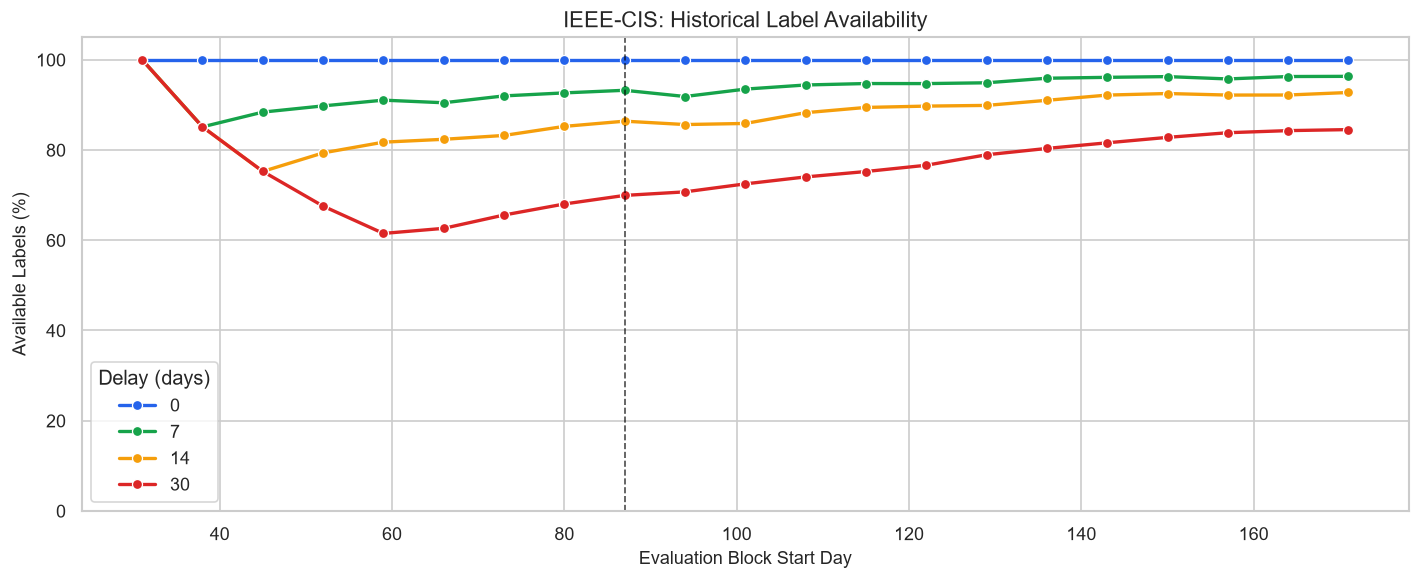

In [40]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=ieee_label_availability,
    x="start_day",
    y="label_availability_pct",
    hue="delay_days",
    palette=IEEE_DELAY_PALETTE,
    marker="o",
    linewidth=2,
    ax=ax,
)

add_ieee_phase_boundary(ax)

ax.set_title("IEEE-CIS: Historical Label Availability")

ax.set_xlabel("Evaluation Block Start Day")

ax.set_ylabel("Available Labels (%)")

ax.set_ylim(0, 105)

ax.legend(title="Delay (days)")

fig.tight_layout()

save_figure(
    fig,
    "ieee_label_availability.png",
)

plt.show()
plt.close(fig)

### Figure 2 — Pending labels

Saved: ieee_pending_labels.png


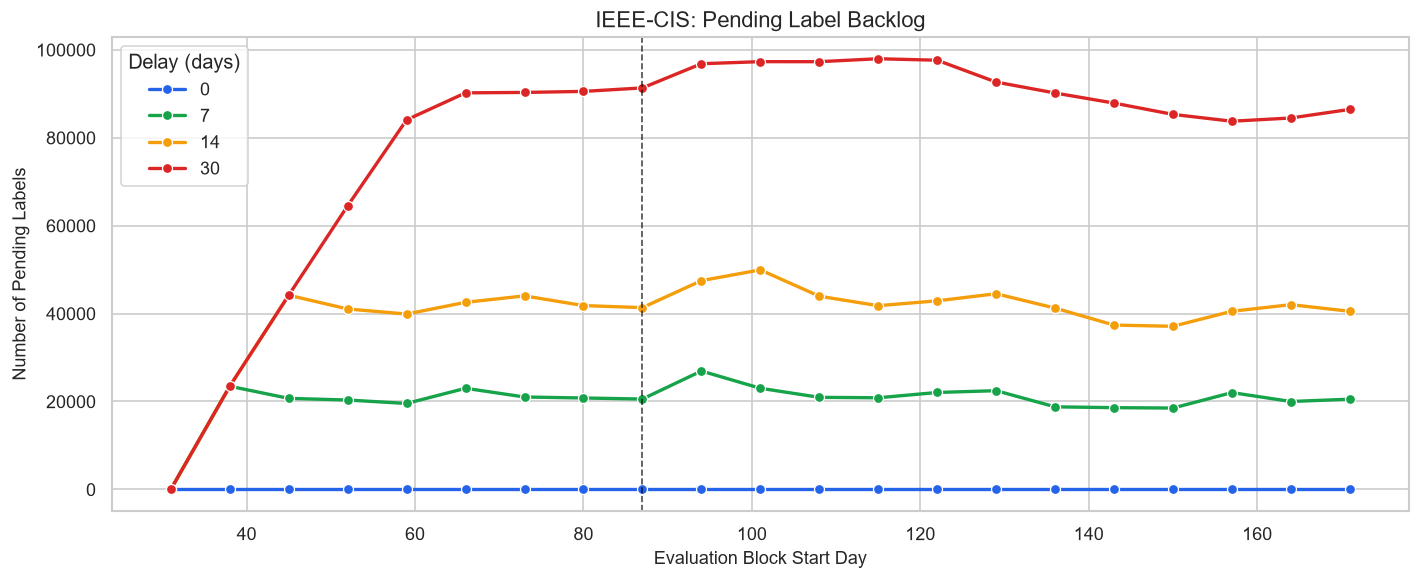

In [41]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=ieee_label_availability,
    x="start_day",
    y="n_pending",
    hue="delay_days",
    palette=IEEE_DELAY_PALETTE,
    marker="o",
    linewidth=2,
    ax=ax,
)

add_ieee_phase_boundary(ax)

ax.set_title("IEEE-CIS: Pending Label Backlog")

ax.set_xlabel("Evaluation Block Start Day")

ax.set_ylabel("Number of Pending Labels")

ax.legend(title="Delay (days)")

fig.tight_layout()

save_figure(
    fig,
    "ieee_pending_labels.png",
)

plt.show()
plt.close(fig)

### Figure 3 — Training sample availability

Saved: ieee_training_samples_w60.png


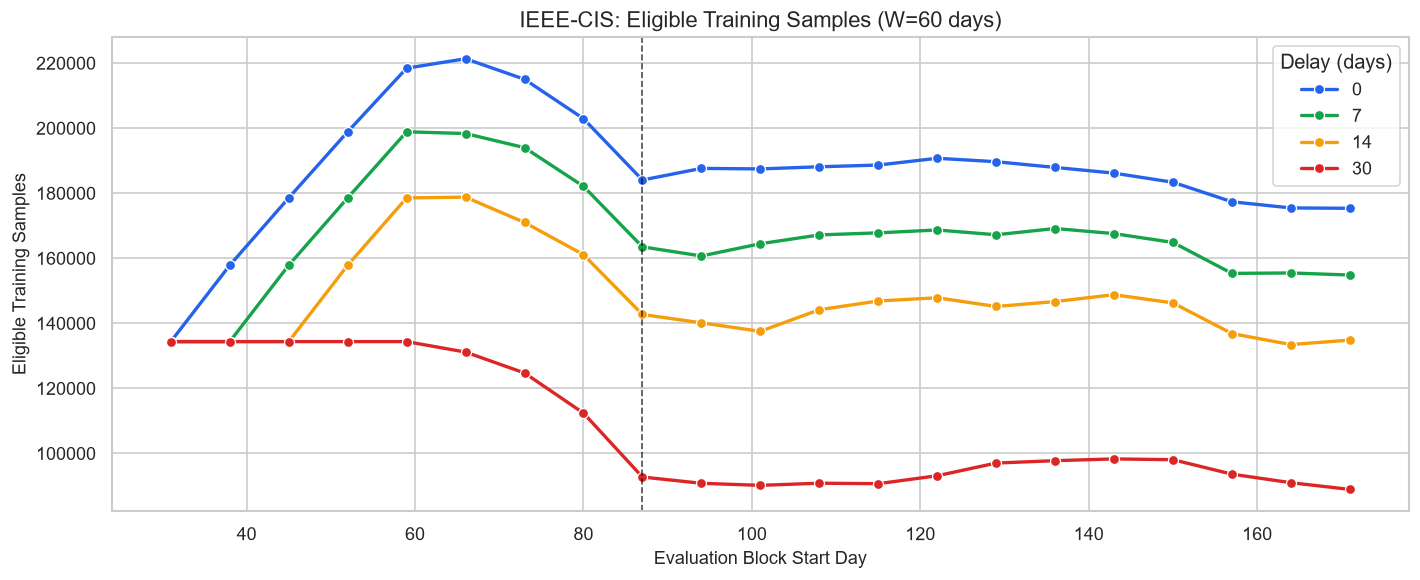

In [42]:
primary_window = sim_cfg["primary_training_window_days"]


ieee_primary_window = ieee_training_availability.loc[
    ieee_training_availability["window_days"].eq(primary_window)
]


fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=ieee_primary_window,
    x="start_day",
    y="n_train",
    hue="delay_days",
    palette=IEEE_DELAY_PALETTE,
    marker="o",
    linewidth=2,
    ax=ax,
)

add_ieee_phase_boundary(ax)

ax.set_title("IEEE-CIS: Eligible Training Samples " f"(W={primary_window} days)")

ax.set_xlabel("Evaluation Block Start Day")

ax.set_ylabel("Eligible Training Samples")

ax.legend(title="Delay (days)")

fig.tight_layout()

save_figure(
    fig,
    "ieee_training_samples_w60.png",
)

plt.show()
plt.close(fig)

### Figure 4 — Available fraud samples

Saved: ieee_training_fraud_w60.png


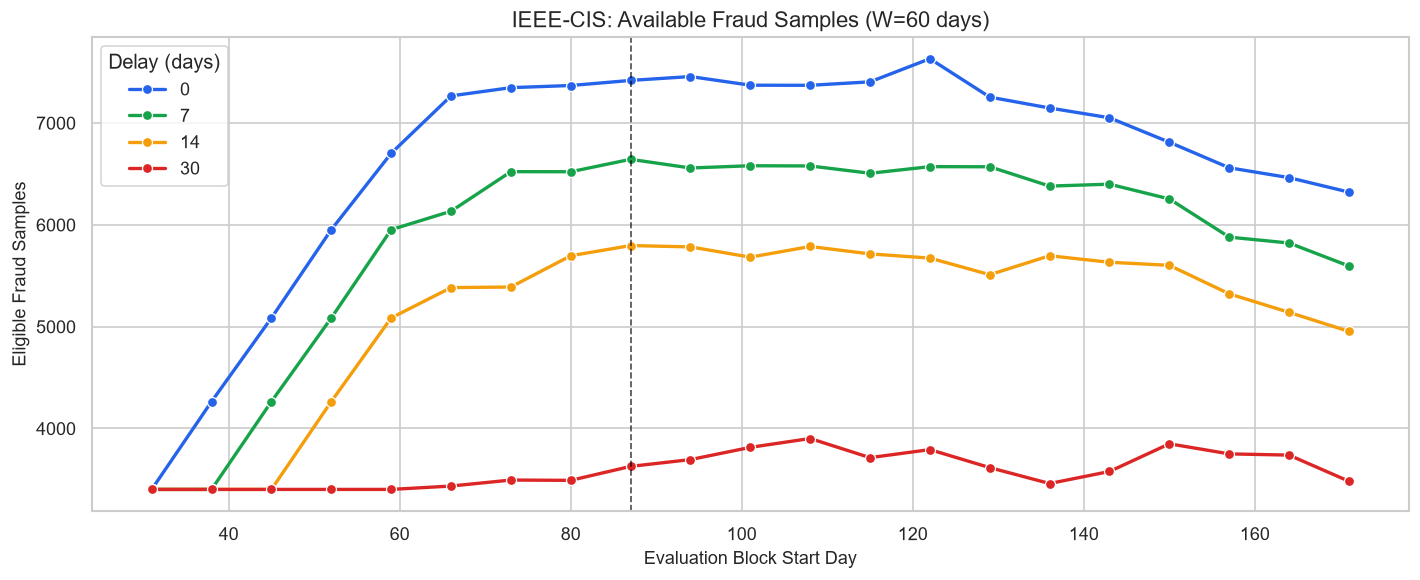

In [43]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.lineplot(
    data=ieee_primary_window,
    x="start_day",
    y="n_train_fraud",
    hue="delay_days",
    palette=IEEE_DELAY_PALETTE,
    marker="o",
    linewidth=2,
    ax=ax,
)

add_ieee_phase_boundary(ax)

ax.set_title("IEEE-CIS: Available Fraud Samples " f"(W={primary_window} days)")

ax.set_xlabel("Evaluation Block Start Day")

ax.set_ylabel("Eligible Fraud Samples")

ax.legend(title="Delay (days)")

fig.tight_layout()

save_figure(
    fig,
    "ieee_training_fraud_w60.png",
)

plt.show()
plt.close(fig)

### Figure 5 — Training availability heatmap

Saved: ieee_training_availability_heatmap.png


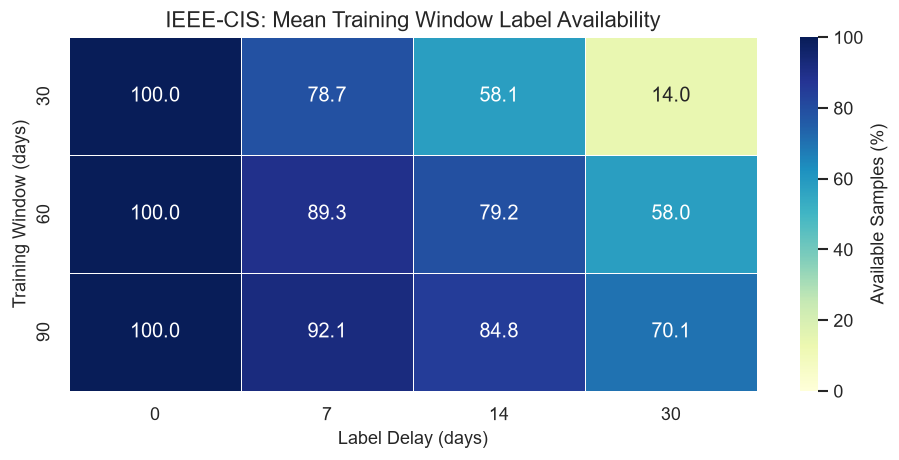

In [44]:
ieee_heatmap = (
    ieee_training_availability.groupby(
        [
            "window_days",
            "delay_days",
        ]
    )["window_label_availability_pct"]
    .mean()
    .unstack("delay_days")
)


fig, ax = plt.subplots(figsize=(8, 4))

sns.heatmap(
    ieee_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Available Samples (%)"},
    ax=ax,
)

ax.set_title("IEEE-CIS: Mean Training Window " "Label Availability")

ax.set_xlabel("Label Delay (days)")

ax.set_ylabel("Training Window (days)")

fig.tight_layout()

save_figure(
    fig,
    "ieee_training_availability_heatmap.png",
)

plt.show()
plt.close(fig)

### Figure 6 — Label starvation

Saved: ieee_label_starvation_w30_d30.png


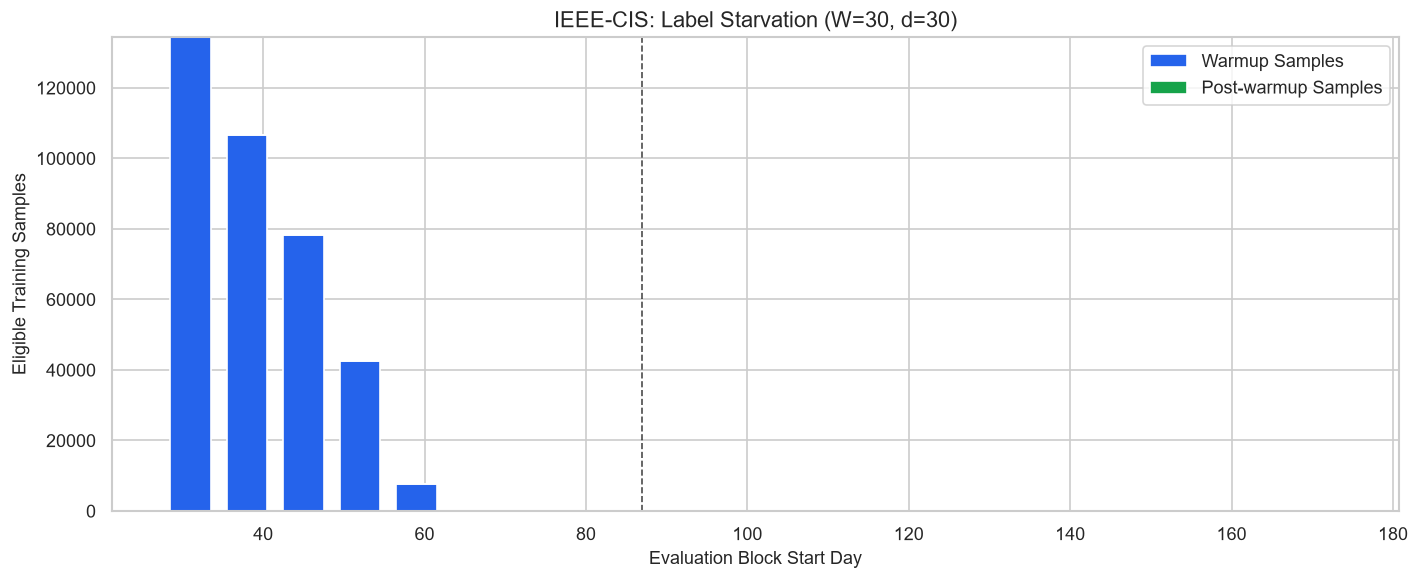

In [45]:
starvation_data = ieee_training_availability.loc[
    ieee_training_availability["window_days"].eq(30)
    & ieee_training_availability["delay_days"].eq(30)
].sort_values("start_day")


fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    starvation_data["start_day"],
    starvation_data["n_train_warmup"],
    width=5,
    label="Warmup Samples",
    color="#2563EB",
)

ax.bar(
    starvation_data["start_day"],
    starvation_data["n_train_post_warmup"],
    bottom=starvation_data["n_train_warmup"],
    width=5,
    label="Post-warmup Samples",
    color="#16A34A",
)

add_ieee_phase_boundary(ax)

ax.set_title("IEEE-CIS: Label Starvation " "(W=30, d=30)")

ax.set_xlabel("Evaluation Block Start Day")

ax.set_ylabel("Eligible Training Samples")

ax.legend()

fig.tight_layout()

save_figure(
    fig,
    "ieee_label_starvation_w30_d30.png",
)

plt.show()
plt.close(fig)

## 11. BAF Visualization

Analyze monthly label availability and training sample
availability independently for all six BAF variants.

BAF monthly results are not directly interpreted as
equivalent to IEEE-CIS daily delay scenarios.

### Figure 7 — BAF label availability

Saved: baf_label_availability.png


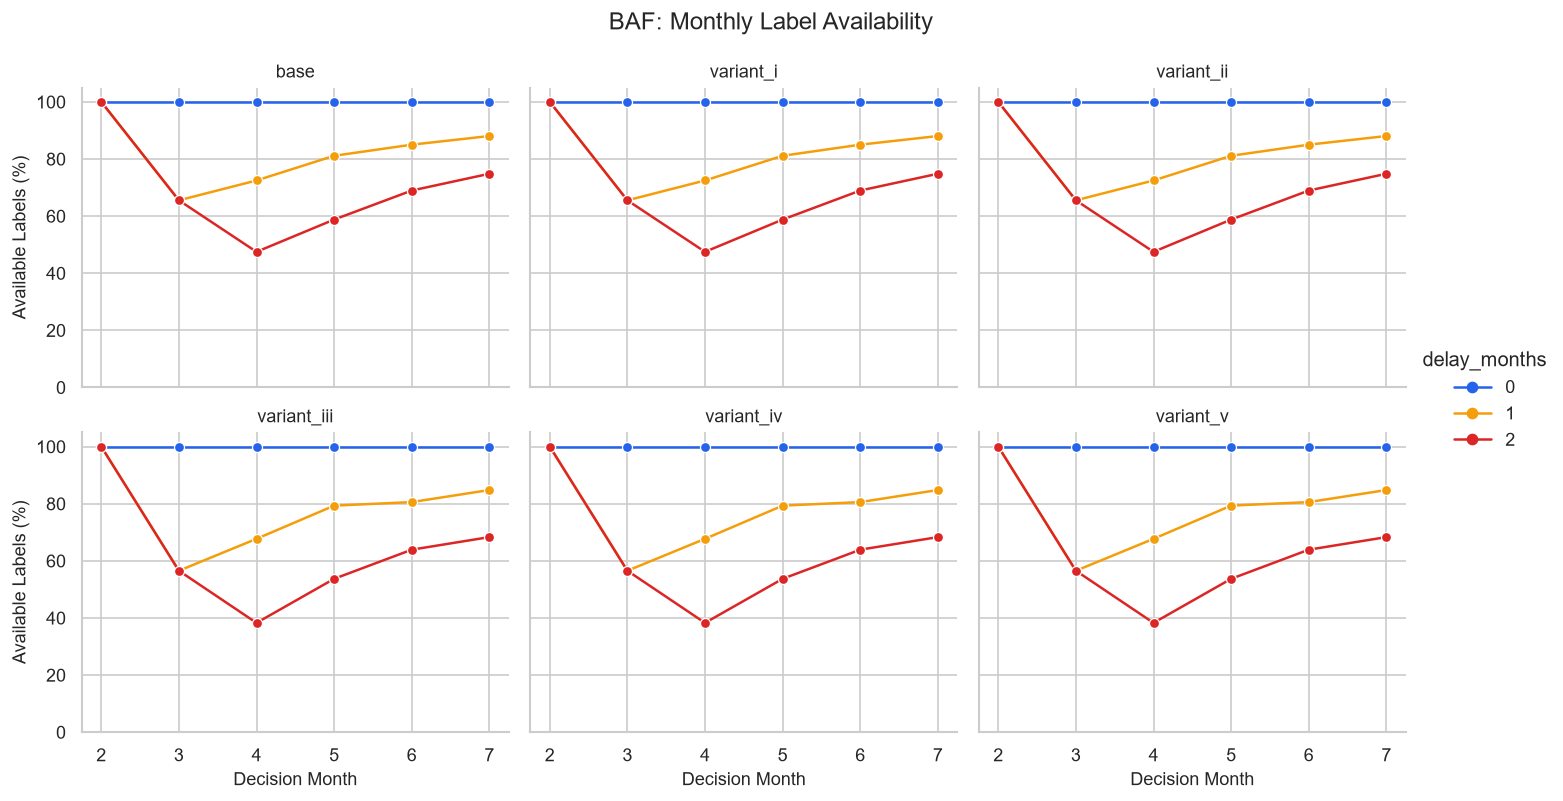

In [46]:
g = sns.relplot(
    data=baf_label_availability,
    x="decision_month",
    y="label_availability_pct",
    hue="delay_months",
    palette=BAF_DELAY_PALETTE,
    col="variant",
    col_order=BAF_VARIANTS,
    col_wrap=3,
    kind="line",
    marker="o",
    height=3.2,
    aspect=1.25,
    facet_kws={
        "sharey": True,
    },
)

g.set_axis_labels(
    "Decision Month",
    "Available Labels (%)",
)

g.set_titles("{col_name}")

g.set(ylim=(0, 105))

g.figure.suptitle(
    "BAF: Monthly Label Availability",
    y=1.04,
)

save_figure(
    g.figure,
    "baf_label_availability.png",
)

plt.show()
plt.close(g.figure)

### Figure 8 — BAF training sample availability

Saved: baf_training_samples_w3.png


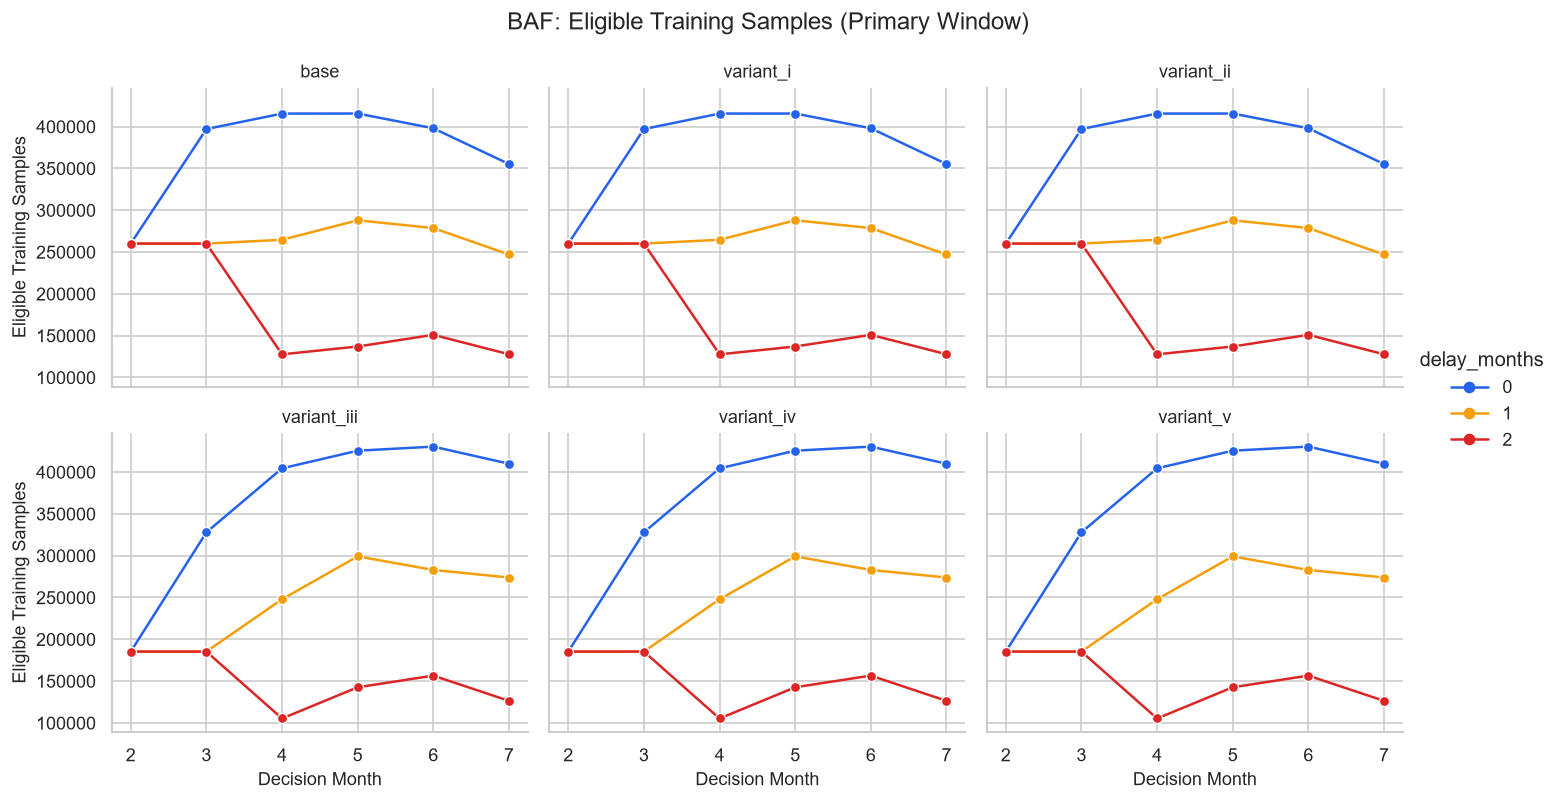

In [47]:
baf_primary_window = baf_training_availability.loc[
    baf_training_availability["window_months"].eq(
        baf_sim_cfg["primary_training_window_months"]
    )
]


g = sns.relplot(
    data=baf_primary_window,
    x="decision_month",
    y="n_train",
    hue="delay_months",
    palette=BAF_DELAY_PALETTE,
    col="variant",
    col_order=BAF_VARIANTS,
    col_wrap=3,
    kind="line",
    marker="o",
    height=3.2,
    aspect=1.25,
    facet_kws={
        "sharey": True,
    },
)

g.set_axis_labels(
    "Decision Month",
    "Eligible Training Samples",
)

g.set_titles("{col_name}")

g.figure.suptitle(
    "BAF: Eligible Training Samples " "(Primary Window)",
    y=1.04,
)

save_figure(
    g.figure,
    "baf_training_samples_w3.png",
)

plt.show()
plt.close(g.figure)

### Figure 9 — BAF available fraud samples

Saved: baf_training_fraud_w3.png


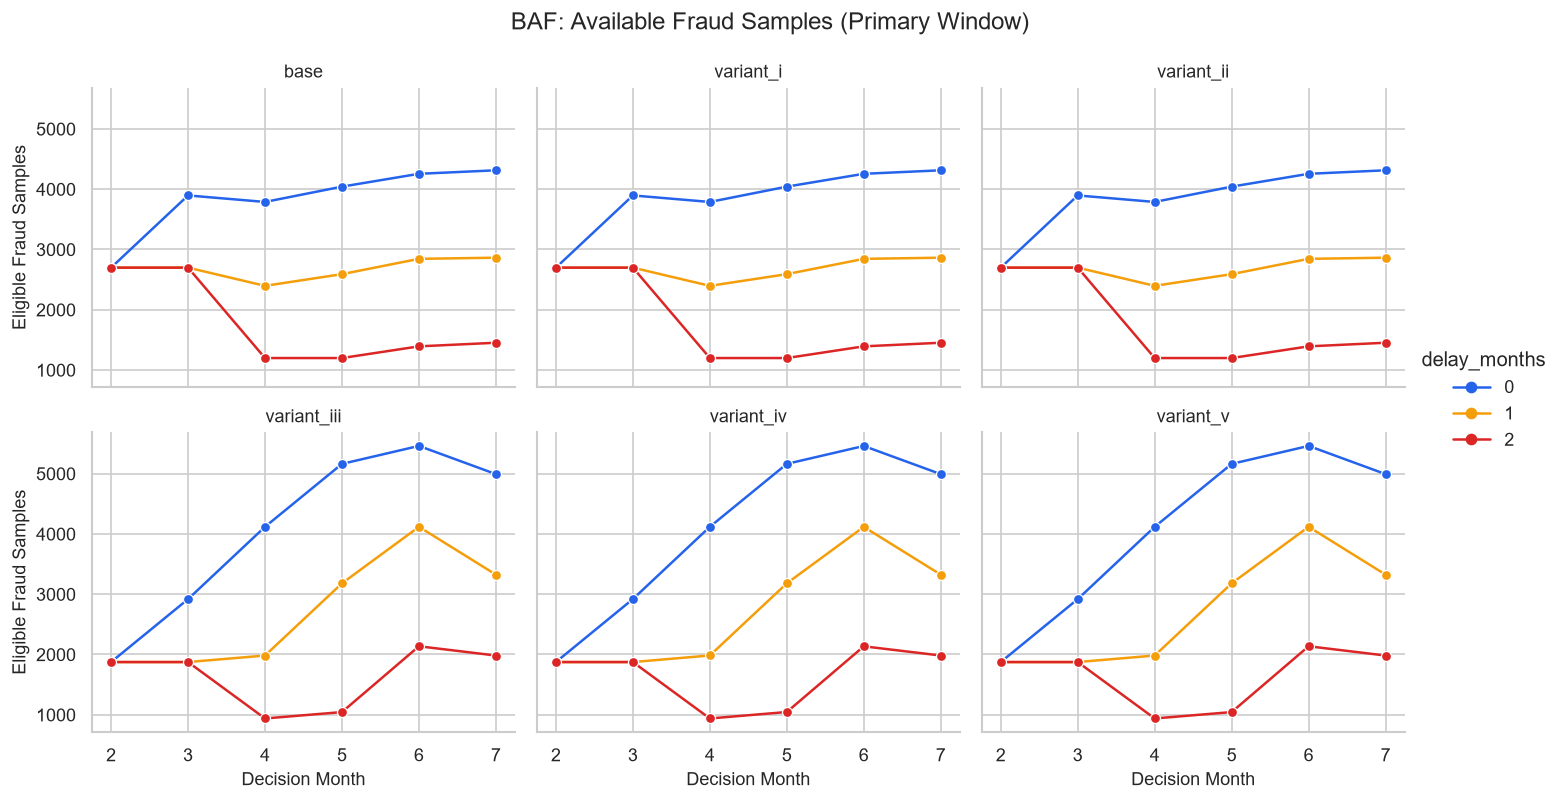

In [48]:
g = sns.relplot(
    data=baf_primary_window,
    x="decision_month",
    y="n_train_fraud",
    hue="delay_months",
    palette=BAF_DELAY_PALETTE,
    col="variant",
    col_order=BAF_VARIANTS,
    col_wrap=3,
    kind="line",
    marker="o",
    height=3.2,
    aspect=1.25,
    facet_kws={
        "sharey": True,
    },
)

g.set_axis_labels(
    "Decision Month",
    "Eligible Fraud Samples",
)

g.set_titles("{col_name}")

g.figure.suptitle(
    "BAF: Available Fraud Samples " "(Primary Window)",
    y=1.04,
)

save_figure(
    g.figure,
    "baf_training_fraud_w3.png",
)

plt.show()
plt.close(g.figure)

## 12. Export Simulation Artifacts

Export label schedule summaries, availability reports,
training availability reports, warmup validation
results, and simulation metadata.

The generated artifacts will be used by subsequent
dataset validation and retraining experiments.

Reports containing retrospective statistics must not
be used as online policy inputs.

### Export CSV reports

In [49]:
reports = {
    "ieee_schedule_summary.csv": ieee_schedule_summary,
    "ieee_label_availability.csv": ieee_label_availability,
    "ieee_training_availability.csv": ieee_training_availability,
    "ieee_training_summary.csv": ieee_training_summary,
    "ieee_warmup_summary.csv": ieee_warmup_summary,
    "baf_schedule_summary.csv": baf_schedule_summary,
    "baf_label_availability.csv": baf_label_availability,
    "baf_training_availability.csv": baf_training_availability,
    "baf_training_summary.csv": baf_training_summary,
    "baf_warmup_summary.csv": baf_warmup_summary,
}


for filename, dataframe in reports.items():

    output_path = REPORT_DIR / filename

    dataframe.to_csv(
        output_path,
        index=False,
    )

    print(f"{filename}: " f"{len(dataframe):,} records")

ieee_schedule_summary.csv: 4 records
ieee_label_availability.csv: 84 records
ieee_training_availability.csv: 252 records
ieee_training_summary.csv: 12 records
ieee_warmup_summary.csv: 4 records
baf_schedule_summary.csv: 18 records
baf_label_availability.csv: 108 records
baf_training_availability.csv: 216 records
baf_training_summary.csv: 36 records
baf_warmup_summary.csv: 18 records


### Check exported schedules

In [50]:
all_schedule_paths = [
    *ieee_schedule_paths.values(),
    *[
        path
        for variant_paths in baf_schedule_paths.values()
        for path in variant_paths.values()
    ],
]


record_validation(
    dataset="all",
    check="expected_schedule_file_count",
    passed=(len(all_schedule_paths) == 22),
)

record_validation(
    dataset="all",
    check="schedule_files_exist",
    passed=all(
        path.is_file() and path.stat().st_size > 0 for path in all_schedule_paths
    ),
)


total_schedule_size_mb = (
    sum(path.stat().st_size for path in all_schedule_paths) / 1024**2
)


print(
    "Schedule files:",
    len(all_schedule_paths),
)

print(f"Total size: " f"{total_schedule_size_mb:.2f} MiB")

Schedule files: 22
Total size: 103.35 MiB


### SHA-256 utility

In [51]:
def calculate_sha256(
    file_path,
    chunk_size=1024 * 1024,
):
    """Calculate SHA-256 without loading entire file."""

    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:

        while True:

            chunk = file.read(chunk_size)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()

### Export validation report

In [52]:
label_delay_validation = pd.DataFrame(validation_records)


validation_path = REPORT_DIR / "label_delay_validation.csv"


label_delay_validation.to_csv(
    validation_path,
    index=False,
)


display(label_delay_validation)


print(
    "Passed checks:",
    int(label_delay_validation["passed"].sum()),
)

print(
    "Failed checks:",
    int((~label_delay_validation["passed"]).sum()),
)

,dataset,check,passed,details
0,ieee_cis,evaluation_block_count,True,21
1,ieee_cis,validation_block_count,True,
2,ieee_cis,test_block_count,True,
3,ieee_cis,weekly_block_length,True,
4,ieee_cis,expected_block_start_days,True,
...,...,...,...,...
134,baf,n_train_window_monotonicity,True,
135,baf,n_train_fraud_delay_monotonicity,True,
136,baf,n_train_fraud_window_monotonicity,True,
137,all,expected_schedule_file_count,True,


Passed checks: 139
Failed checks: 0


### Generate simulation metadata

In [53]:
schedule_artifacts = []


for path in all_schedule_paths:

    schedule_artifacts.append(
        {
            "path": str(path.relative_to(PROJECT_ROOT)),
            "size_bytes": (path.stat().st_size),
            "sha256": calculate_sha256(path),
        }
    )


input_artifacts = []


for path in required_paths:

    input_artifacts.append(
        {
            "path": str(path.relative_to(PROJECT_ROOT)),
            "size_bytes": (path.stat().st_size),
            "sha256": calculate_sha256(path),
        }
    )


metadata = {
    "stage": "label_delay_simulation",
    "created_at_utc": (datetime.now(timezone.utc).isoformat()),
    "config": {
        "path": "configs/dataset.yaml",
        "sha256": calculate_sha256(PROJECT_ROOT / "configs" / "dataset.yaml"),
    },
    "source_code": {
        "path": "src/label_delay.py",
        "sha256": calculate_sha256(PROJECT_ROOT / "src" / "label_delay.py"),
    },
    "ieee_cis": {
        "simulation_version": (sim_cfg["version"]),
        "time_unit": "seconds",
        "delay_unit": "days",
        "delay_scenarios": IEEE_DELAYS,
        "training_windows": IEEE_WINDOWS,
        "warmup_strategy": (sim_cfg["warmup_strategy"]),
        "training_window_strategy": (sim_cfg["training_window_strategy"]),
        "label_availability_rule": (sim_cfg["label_availability_rule"]),
        "deployment_time": (ieee_deployment_time),
        "include_tail_in_schedule": (sim_cfg["include_tail_in_schedule"]),
        "include_tail_in_training": (sim_cfg["include_tail_in_training"]),
        "n_evaluation_blocks": int(len(ieee_decisions)),
        "n_schedules": int(len(ieee_schedule_summary)),
        "n_availability_records": int(len(ieee_label_availability)),
        "n_training_records": int(len(ieee_training_availability)),
    },
    "baf": {
        "simulation_version": (baf_sim_cfg["version"]),
        "time_unit": "months",
        "delay_unit": "months",
        "variants": BAF_VARIANTS,
        "delay_scenarios": BAF_DELAYS,
        "training_windows": BAF_WINDOWS,
        "warmup_strategy": (baf_sim_cfg["warmup_strategy"]),
        "training_window_strategy": (baf_sim_cfg["training_window_strategy"]),
        "label_release_strategy": (baf_sim_cfg["label_release_strategy"]),
        "label_availability_rule": (baf_sim_cfg["label_availability_rule"]),
        "n_schedules": int(len(baf_schedule_summary)),
        "n_availability_records": int(len(baf_label_availability)),
        "n_training_records": int(len(baf_training_availability)),
    },
    "retrospective_metrics": {
        "column_prefix": "offline_",
        "allowed_for_online_policy": False,
    },
    "validation": {
        "n_checks": int(len(label_delay_validation)),
        "n_passed": int(label_delay_validation["passed"].sum()),
        "n_failed": int((~label_delay_validation["passed"]).sum()),
    },
    "input_artifacts": input_artifacts,
    "schedule_artifacts": schedule_artifacts,
    "environment": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
}


metadata_path = REPORT_DIR / "label_delay_metadata.json"


with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        metadata,
        file,
        indent=2,
        ensure_ascii=False,
    )


print(
    "Metadata saved:",
    metadata_path,
)

Metadata saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\label_delay\label_delay_metadata.json


## 13. Final Summary

Summarize generated label schedules, training availability
experiments, and validation results.

This notebook prepares the delayed-label data access
protocol required for subsequent model training and
retraining policy experiments.

In [54]:
final_summary = pd.DataFrame(
    [
        {
            "dataset": "IEEE-CIS",
            "n_variants": 1,
            "n_delay_scenarios": len(IEEE_DELAYS),
            "n_training_windows": len(IEEE_WINDOWS),
            "n_schedule_files": len(ieee_schedule_summary),
            "n_availability_records": len(ieee_label_availability),
            "n_training_records": len(ieee_training_availability),
            "n_empty_training_cases": int(
                ieee_training_availability["status"].eq("empty").sum()
            ),
        },
        {
            "dataset": "BAF",
            "n_variants": len(BAF_VARIANTS),
            "n_delay_scenarios": len(BAF_DELAYS),
            "n_training_windows": len(BAF_WINDOWS),
            "n_schedule_files": len(baf_schedule_summary),
            "n_availability_records": len(baf_label_availability),
            "n_training_records": len(baf_training_availability),
            "n_empty_training_cases": int(
                baf_training_availability["status"].eq("empty").sum()
            ),
        },
    ]
)


display(final_summary)


assert label_delay_validation["passed"].all(), "Validation checks failed."


print("=" * 60)
print("LABEL DELAY SIMULATION COMPLETED")
print("=" * 60)

print(
    "Schedule files:",
    len(all_schedule_paths),
)

print(
    "Availability records:",
    len(ieee_label_availability) + len(baf_label_availability),
)

print(
    "Training availability records:",
    len(ieee_training_availability) + len(baf_training_availability),
)

print(
    "Validation checks:",
    len(label_delay_validation),
)

print("All recorded checks passed.")

,dataset,n_variants,n_delay_scenarios,n_training_windows,n_schedule_files,n_availability_records,n_training_records,n_empty_training_cases
0,IEEE-CIS,1,4,3,4,84,252,16
1,BAF,6,3,2,18,108,216,24


LABEL DELAY SIMULATION COMPLETED
Schedule files: 22
Availability records: 192
Training availability records: 468
Validation checks: 139
All recorded checks passed.


## 14. Conclusion

The delayed-label simulation pipeline provides
deterministic label schedules for IEEE-CIS and BAF.

The generated reports quantify the amount of historical
and recent training data available under different
label-delay and training-window configurations.

The common pre-labeled warmup protocol ensures that
all delay scenarios can share the same initial
training dataset.

Temporal eligibility checks prevent the use of future
transactions and unavailable labels.

Retrospective diagnostic metrics are explicitly
separated from information available to online
retraining policies.

The next stage performs independent unit tests,
integration tests, and final dataset validation.